# Reporte técnico
## Mercado automotriz de La Habana: dos caminos para comprar un carro

**Proyecto:** Ciencia de Datos (1er año) · Universidad de La Habana  
**Autor:** Daniel Fajardo  
**Fecha:** noviembre de 2026  
**Versión:** 2.0 — reporte ampliado y reproducible  
**Repositorio:** `ProyectoCD` · commit de referencia `dc0951a`  
**Alcance:** La Habana (15 municipios), datos de 2026

> Documento técnico y notebook reproducible. Todas las cifras se calculan desde los CSV del proyecto y se verifican en las celdas de control. No se inventan datos: lo que falta queda como ausente y se excluye del cálculo correspondiente.

---

**Cómo citar este documento**

> Fajardo, D. (2026). *Mercado automotriz de La Habana: dos caminos para comprar un carro. Reporte técnico*. Proyecto de Ciencia de Datos, Universidad de La Habana.

## Resumen

Este reporte analiza el mercado automotriz de La Habana a partir de tres fuentes construidas para el proyecto: **3.566 anuncios de Revolico** (mercado informal), **83 modelos de catálogos de comercializadoras** (mercado formal) y **30 entrevistas procesadas** sobre costos de mantenimiento. El objetivo es caracterizar la oferta, los precios y la brecha entre canales, con reglas explícitas de limpieza y medidas robustas.

Tras excluir **584 precios marcador** y **279 anuncios sin precio**, la mediana del mercado informal es **22.000 USD** (n=2.703) y la del formal **32.699 USD** (83 modelos de catálogo): una brecha de **10.699 USD**. La diferencia sobrevive a la limpieza, pero no debe leerse como “el mismo carro cuesta distinto”: el catálogo formal es nuevo y el informal mezcla usados, versiones y estados.

La oferta se concentra en **Playa** (1.002 anuncios, 28,1%) y en **Hyundai** (872 anuncios, 24,5%). El **48,9%** de los anuncios no declara año y el **31,1%** no declara marca, dos límites centrales para cualquier conclusión. En las entrevistas, el gasto anual declarado en mantenimiento va de **200 a 3.000 USD**, con una variación que depende del vehículo, el uso y la disponibilidad de piezas.

**Palabras clave:** mercado automotriz, La Habana, precios, Revolico, comercializadoras, datos faltantes, estadística robusta, mercado informal.

## Índice

1. Introducción
2. Marco conceptual y definiciones
3. Datos y metodología
4. Resultados (Q1–Q9)
5. Discusión
6. Limitaciones
7. Conclusiones
8. Referencias
9. Anexos

> **Convención:** cada figura y tabla declara su fuente y su `n`. Los precios se expresan en USD. La mediana es la medida de referencia; la media recortada al 10% se usa como chequeo de robustez.

## 1. Introducción

### 1.1 Contexto

Comprar un carro en La Habana implica elegir entre dos caminos que no siempre son comparables. El primero es el **canal formal**: comercializadoras autorizadas que publican catálogos con precios de lista, modelos nuevos y una oferta limitada. El segundo es el **canal informal**: anuncios clasificados —principalmente Revolico— donde personas y pequeños negocios publican autos usados, nuevos y “ofertas” con información desigual.

No existe un dataset público y completo de este mercado. Por eso el proyecto **construye sus propios datos** combinando captura web, verificación de catálogos y entrevistas. Esa decisión implica asumir límites: una muestra no es el mercado entero, un precio pedido no es un precio de cierre y un anuncio no es una venta.

### 1.2 Problema

El comprador habanero enfrenta tres problemas de información:

1. **Precios dispersos y poco comparables.** Un mismo modelo puede aparecer con precios muy distintos según año, estado, versión y urgencia del vendedor.
2. **Datos incompletos.** Casi la mitad de los anuncios no declara año; el kilometraje, el estado mecánico y los papeles suelen faltar.
3. **Dos canales con lógicas distintas.** El precio de lista formal y el precio pedido informal no miden lo mismo.

### 1.3 Objetivos

**Objetivo general:** caracterizar la estructura y los precios del mercado automotriz de La Habana en sus canales formal e informal, con especial atención a la brecha entre ambos y a los límites de los datos.

**Objetivos específicos:**

- Describir la composición de la oferta por marca, municipio y antigüedad.
- Estimar precios típicos con medidas robustas y reportar la calidad de la muestra informal.
- Comparar el canal formal y el informal solo donde el cruce es defendible.
- Documentar el costo de mantenimiento declarado por 30 propietarios.
- Dejar un pipeline reproducible y declarar todos los sesgos.

### 1.4 Preguntas de investigación

| # | Pregunta | Variable principal | Enfoque |
|---|---|---|---|
| Q1 | ¿Cuál es la marca con mayor índice de publicaciones? | `marca` | Conteo; proxy de anuncios, no de ventas |
| Q2 | ¿Cuál es el promedio de precios por marca? | `precio_usd`, `marca` | Mediana y media recortada al 10%, con `n` |
| Q3 | ¿Existe relación entre precio y año? | `precio_usd`, `anio` | Correlación, tendencia y medianas por década |
| Q4 | ¿Cuál es la marca con precios más elevados? | `precio_usd`, `marca` | Mediana por marca con `n≥30` |
| Q5 | ¿Qué proporción de clásicos y modernos hay? | `anio` | Criterio: clásico <2000, moderno ≥2000 |
| Q6 | ¿Cuál es la diferencia formal vs. informal? | `mercado`, `precio_usd` | Brecha de medianas y cruce por marca |
| Q7 | ¿Cuál es el municipio con más publicaciones? | `municipio` | Conteo |
| Q8 | ¿Existe relación entre municipio y precio? | `municipio`, `precio_usd` | Mediana por municipio y prueba no paramétrica |
| Q9 | ¿Cuánto cuesta mantener un auto? | Entrevistas | Análisis descriptivo/cualitativo de 30 casos |

> **Q1 se documenta como proxy.** El conteo de anuncios mide publicaciones en una plataforma, no ventas ni participación de mercado.

### 1.5 Alcance y delimitación

- **Geografía:** solo La Habana (15 municipios). Los datos nacionales en crudo no se extrapolan.
- **Período:** anuncios capturados entre septiembre y octubre de 2026; catálogos formales consultados entre el 31 de marzo y el 2 de noviembre de 2026; entrevistas procesadas en 2026.
- **Unidad de análisis:** el anuncio (informal) y el modelo de catálogo (formal), no la transacción.
- **Moneda:** USD, con conversiones documentadas (710 CUP/USD; 1,120529 EUR/USD).

### 1.6 Aporte

El aporte es triple: (a) un dataset construido y documentado para un mercado sin datos públicos; (b) una comparación formal-informal con reglas explícitas y cautelas; (c) un conjunto de productos reproducibles (notebook, figuras, página web) que permiten auditar cada cifra.

> **La página web `web/` es un producto de comunicación complementario.** Este reporte debe leerse de forma autónoma: contiene los métodos, las tablas, las figuras y las referencias.

## 2. Marco conceptual y definiciones

### 2.1 Dos canales, dos lógicas

| Dimensión | Canal informal (Revolico) | Canal formal (comercializadoras) |
|---|---|---|
| Qué se publica | Autos usados, nuevos y ofertas | Modelos nuevos de catálogo |
| Precio | **Pedido** por el vendedor | **De lista o referencia** |
| Negociación | Alta, no observada | Baja o inexistente |
| Información | Incompleta y heterogénea | Ficha de modelo |
| Cobertura | Anuncios de una plataforma | Catálogo de 4 entidades |

**Consecuencia metodológica:** comparar ambos canales es comparar **productos distintos**. La brecha de precios es un hecho descriptivo, no una medida de “sobreprecio” ni una relación causal.

### 2.2 Precio pedido, precio de lista y precio de cierre

- **Precio pedido:** lo que el vendedor publica. No incorpora descuentos, regateo ni condiciones de pago.
- **Precio de lista:** lo que la comercializadora publica como referencia. Puede variar por versión, equipamiento o disponibilidad.
- **Precio de cierre:** lo que efectivamente se paga. **No se observa en este proyecto.**

Por eso el reporte habla de “precios pedidos” y “precios de lista”, nunca de “precios de mercado” como si fueran transacciones.

### 2.3 Medidas robustas

La distribución de precios es asimétrica: convive un Lada de 5.000 USD con un BMW de 46.000 USD y valores extremos de 320.000 USD. La media aritmética es sensible a esos extremos; la mediana y la media recortada no.

- **Mediana:** valor central. Medida de referencia del proyecto.
- **Media recortada al 10%:** se ordenan los datos, se elimina 10% por cada cola y se promedia el resto. Chequeo de robustez.
- **Rango intercuartílico (P25–P75):** dispersión del 50% central.
- **Calidad de muestra (solo informal):** `n≥30` suficiente; `10≤n<30` baja; `n<10` insuficiente. El catálogo formal no es una muestra: es la lista de modelos publicados.

### 2.4 Definiciones operativas

| Término | Definición en este proyecto |
|---|---|
| Precio válido | `1.000 ≤ precio_usd < 1.000.000` |
| Precio marcador | Valor fuera de ese rango (p. ej. 1 USD o 1.111.111 USD) |
| Marca no identificada | `marca` nula o “no identificada”; se excluye de análisis por marca |
| Año ausente | `anio == 0`; no se imputa |
| Clásico | `anio < 2000` |
| Moderno | `anio ≥ 2000` |
| Muestra informal suficiente | `n ≥ 30` |
| Marca comparable | `n ≥ 10` en ambos canales |

## 3. Datos y metodología

### 3.1 Fuentes y período

| Fuente | Tipo | Período | Registros | Uso |
|---|---|---|---:|---|
| Revolico | Anuncios clasificados | sep–oct 2026 | 3.566 (La Habana) | Mercado informal |
| BDC ONE | Catálogo formal | 2026 | 13 modelos | Mercado formal |
| Dongfeng Cuba | Catálogo formal | 2026 | 27 modelos | Mercado formal |
| MCV Comercial | Catálogo formal | 2026 | 37 modelos | Mercado formal |
| CIMEX | Catálogo formal | 2026 | 6 modelos | Mercado formal |
| Entrevistas | Resúmenes procesados | 2026 | 30 casos | Q9 |

**Datasets analíticos:**

- `data/interim/anuncios_analisis.csv` — 3.566 anuncios de La Habana, 22 columnas.
- `data/processed/comercializadoras.csv` — 83 modelos formales, 16 columnas.
- `data/raw/entrevistas/Entrevistas.txt` — 30 entrevistas procesadas (resúmenes, no verbatim).
- `data/raw/clasificados/revolico/verificacion_anuncios.csv` — 3.958 URLs verificadas el 2026-10-26.

### 3.2 Captura y verificación

- **Revolico:** la API GraphQL del sitio se descubrió por ingeniería inversa de los bundles. La captura recorrió 79 páginas de 50 anuncios con pausa de 4 s, sin guardar teléfonos ni datos de contacto.
- **Comercializadoras:** verificación HTTP+DNS y extracción de catálogos con precios públicos. BDC ONE y Dongfeng son HTML estático; MCV se extrajo de su tienda; CIMEX se incorporó desde su catálogo.
- **Verificación de anuncios:** se consultaron 3.958 URLs el 2026-10-26. Resultado: 3.102 con HTTP 200, 839 con error de conexión y 17 con timeout. **Un error de red no equivale a anuncio despublicado.**
- **Entrevistas:** 30 conversaciones procesadas a resúmenes; no se publican datos personales ni transcripciones completas.

### 3.3 Flujo de trabajo (7 etapas)

| Etapa | Nombre | Artefacto |
|---|---|---|
| 01 | Capturar | `src/scraper_revolico*.py`, `src/scraper_comercializadoras.py` |
| 02 | Preprocesar | `src/preprocesamiento.py`, `notebooks/01_preprocesamiento.ipynb` |
| 03 | Estructurar y almacenar | `data/processed/`, `docs/diccionario_datos.md` |
| 04 | Procesar | `src/generar_variables.py` |
| 05 | Analizar | `notebooks/02_preguntas.ipynb`, este reporte |
| 06 | Presentar | `reports/figuras/`, `reports/tablas/` |
| 07 | Comunicar | `web/` (página estática) |

### 3.4 Reglas de inclusión y exclusión

| Regla | Aplicación | Efecto |
|---|---|---|
| Solo La Habana | `provincia == "La Habana"` | 3.566 anuncios |
| Precio válido | `1.000 ≤ precio_usd < 1.000.000` | 2.703 conservados; 584 excluidos; 279 nulos |
| Marca válida | Excluir “no identificada” | 1.110 anuncios fuera de análisis por marca |
| Año válido | `anio > 0` para análisis por año | 1.745 fuera; 1.821 conservados |
| Microbús/Pickup | No tratar como marca en gráficos por marca | 2 filas formales |
| Sin imputación | No se rellenan faltantes | Los `n` reflejan cada análisis |
| Sin duplicados | `anuncio_id` y `url` únicos | 0 duplicados |

### 3.5 Variables principales

| Variable | Tipo | Descripción |
|---|---|---|
| `precio_usd` | float | Precio convertido a USD |
| `marca` | texto | Marca normalizada; “no identificada” si falta |
| `modelo` | texto | Modelo detectado (puede contener ruido) |
| `anio` | int | Año de fabricación; 0 = ausente |
| `municipio` | texto | Municipio de La Habana |
| `vistas` | int | Visualizaciones del anuncio |
| `estado_verificacion` | texto | activo / error / despublicado / eliminado / expirado |
| `entidad` | texto | Comercializadora (solo formal) |
| `propulsion` | texto | Gasolina, diésel, eléctrico, híbrido, etc. |

> Diccionario completo: `docs/diccionario_datos.md`.

### 3.6 Métodos

- **Descriptivos:** conteos, porcentajes, mediana, P25/P75, media recortada.
- **Asociación:** Pearson y Spearman para precio-año; OLS y Theil-Sen como sensibilidad.
- **Comparación de grupos:** Kruskal-Wallis para precio por municipio (con cautela por confusión).
- **Cualitativo:** síntesis de las 30 entrevistas; conteo de respuestas declaradas y no declaradas.

No se usan modelos predictivos como conclusión: el objetivo es describir, no predecir precios de cierre.

### 3.7 Reproducibilidad y ética

- **Entorno:** Python 3.14.8; `requirements-lock.txt`.
- **Commit:** la celda de entorno imprime el hash actual.
- **Semillas:** no hay modelos estocásticos en este reporte; los análisis son deterministas.
- **Datos personales:** no se guardan teléfonos ni contactos; las entrevistas se presentan como resúmenes.
- **Correcciones:** las figuras 03, 04 y 07 se regeneraron para corregir la etiqueta Foton/Ford, mostrar `n` y evitar el ranking de entidades.

In [1]:
%matplotlib inline
from pathlib import Path
import subprocess
import sys
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
from IPython.display import Image, display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data"
IMG = ROOT / "web" / "img"
FIG = ROOT / "reports" / "figuras" / "Analizar"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({
    "figure.figsize": (9.5, 5.6),
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

def fmt_int(v):
    if pd.isna(v):
        return "—"
    return f"{int(round(v)):,}".replace(",", ".")

def fmt_usd(v):
    if pd.isna(v):
        return "—"
    return f"{fmt_int(v)} USD"

def fmt_pct(v):
    if pd.isna(v):
        return "—"
    return f"{v:.1f} %".replace(".", ",")

def tabla(df, enteros=(), usd=(), pct=(), dec=(), titulo=None):
    if titulo:
        display(Markdown(f"**{titulo}**"))
    out = df.copy()
    for c in enteros:
        out[c] = out[c].map(fmt_int)
    for c in usd:
        out[c] = out[c].map(fmt_usd)
    for c in pct:
        out[c] = out[c].map(fmt_pct)
    for c in dec:
        out[c] = out[c].map(lambda v: f"{v:.2f}".replace(".", ",") if pd.notna(v) else "—")
    display(out)

def mostrar_figura(nombre, ancho=900, titulo=None):
    for base in (IMG, FIG):
        ruta = base / nombre
        if ruta.exists():
            display(Image(filename=str(ruta), width=ancho))
            if titulo:
                display(Markdown(f"*{titulo}*"))
            return
    print(f"[AVISO] No se encontró la figura: {nombre}")

def media_recortada(serie, prop=0.10):
    s = serie.dropna().sort_values()
    if s.empty:
        return np.nan
    k = int(len(s) * prop)
    return s.iloc[k:len(s)-k].mean() if k else s.mean()

MARCAS = {
    "bmw": "BMW", "mg": "MG", "gmc": "GMC", "jac": "JAC", "jmc": "JMC",
    "gac": "GAC", "byd": "BYD", "baic": "BAIC", "dfsk": "DFSK",
    "maxus": "MAXUS", "mini": "MINI", "mercedes-benz": "Mercedes-Benz",
    "land rover": "Land Rover", "no identificada": "No identificada",
}
MUNICIPIOS = {
    "arroyo naranjo": "Arroyo Naranjo", "boyeros": "Boyeros",
    "centro habana": "Centro Habana", "cerro": "Cerro", "cotorro": "Cotorro",
    "diez de octubre": "Diez de Octubre", "guanabacoa": "Guanabacoa",
    "habana del este": "Habana del Este", "habana vieja": "Habana Vieja",
    "la lisa": "La Lisa", "marianao": "Marianao", "playa": "Playa",
    "plaza": "Plaza", "regla": "Regla", "san miguel del padrón": "San Miguel del Padrón",
}

def etiqueta_marca(valor):
    valor = str(valor).strip().lower()
    return MARCAS.get(valor, valor.title())

def etiqueta_municipio(valor):
    valor = str(valor).strip().lower()
    return MUNICIPIOS.get(valor, valor.title())

a = pd.read_csv(DATA / "interim" / "anuncios_analisis.csv", encoding="utf-8-sig")
c = pd.read_csv(DATA / "processed" / "comercializadoras.csv", encoding="utf-8-sig")

a["precio_usd"] = pd.to_numeric(a["precio_usd"], errors="coerce")
a["anio"] = pd.to_numeric(a["anio"], errors="coerce").fillna(0).astype(int)
a["marca"] = a["marca"].fillna("no identificada").astype(str).str.strip().str.lower()
a["municipio"] = a["municipio"].fillna("sin dato").astype(str).str.strip().str.lower()

c["precio_usd"] = pd.to_numeric(c["precio_usd"], errors="coerce")
c["marca"] = c["marca"].fillna("no identificada").astype(str).str.strip()
if "marca_norm" in c.columns:
    c["marca_web"] = c["marca_norm"].fillna(c["marca"].str.lower()).astype(str).str.lower().str.strip()
else:
    c["marca_web"] = c["marca"].str.lower()

completo = (a["precio_usd"] >= 1_000) & (a["precio_usd"] < 1_000_000)
va = a[completo].copy()

try:
    commit = subprocess.run(
        ["git", "rev-parse", "--short", "HEAD"],
        cwd=ROOT, capture_output=True, text=True, check=True
    ).stdout.strip()
except Exception:
    commit = "no disponible"

print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · numpy {np.__version__} · matplotlib {matplotlib.__version__}")
print(f"Commit analizado: {commit}")
print(f"Anuncios: {len(a):,} · precios válidos: {int(completo.sum()):,} · formal: {len(c):,}")
print(f"Ruta del proyecto: {ROOT}")

Python 3.14.8 · pandas 3.0.5 · numpy 2.5.3 · matplotlib 3.11.2
Commit analizado: fd392e7
Anuncios: 3,566 · precios válidos: 2,703 · formal: 83
Ruta del proyecto: /home/silver/Projects/ProyectoCD


### 3.8 Control de calidad del dataset

Antes de analizar, conviene fijar el tamaño y las exclusiones. La siguiente tabla es la **fuente de verdad** de los `n` que aparecen en el resto del reporte.

In [2]:
p = a["precio_usd"]
total = len(a)
control = pd.DataFrame([
    ("Anuncios de La Habana", total, "100,0 %", "total del dataset"),
    ("Con precio válido (1.000–999.999 USD)", int(completo.sum()), "75,8 %", "base de los análisis de precio"),
    ("Precio nulo", int(p.isna().sum()), "7,8 %", "no se imputa"),
    ("Precio < 1.000 USD", int((p < 1_000).sum()), "16,3 %", "marcador o error"),
    ("Precio ≥ 1.000.000 USD", int((p >= 1_000_000).sum()), "0,1 %", "marcador"),
    ("Sin marca identificada", int((a["marca"] == "no identificada").sum()), "31,1 %", "excluida en análisis por marca"),
    ("Sin año declarado", int((a["anio"] == 0).sum()), "48,9 %", "excluido en análisis por año"),
    ("Sin municipio", int((a["municipio"] == "sin dato").sum()), "0,1 %", "excluido en análisis territorial"),
    ("Estado: activo", int((a["estado_verificacion"] == "activo").sum()), "74,3 %", "verificación 2026-10-26"),
    ("Estado: error de verificación", int((a["estado_verificacion"] == "error").sum()), "22,7 %", "fallo de red, no implica no disponible"),
    ("Estado: despublicado", int((a["estado_verificacion"] == "despublicado").sum()), "1,9 %", "retirado"),
    ("Estado: eliminado", int((a["estado_verificacion"] == "eliminado").sum()), "1,0 %", "retirado por el anunciante"),
    ("Estado: expirado", int((a["estado_verificacion"] == "expirado").sum()), "0,1 %", "vigencia vencida"),
    ("Duplicados por anuncio_id", int(a["anuncio_id"].duplicated().sum()), "0,0 %", "control"),
    ("Duplicados por URL", int(a["url"].duplicated().sum()), "0,0 %", "control"),
], columns=["Indicador", "Valor", "% del total", "Nota"])

tabla(control, enteros=["Valor"], titulo="Tabla 3.1. Control de calidad del dataset (La Habana, 2026).")

estado = (
    a.assign(valido=completo)
     .groupby("estado_verificacion")
     .agg(Anuncios=("anuncio_id", "size"), Con_precio_valido=("valido", "sum"))
     .sort_values("Anuncios", ascending=False)
     .reset_index()
)
print("\nEstado de verificación y precio válido:")
tabla(estado, enteros=["Anuncios", "Con_precio_valido"], titulo="Tabla 3.2. Estado de verificación y precio válido.")

activo = a[(a["estado_verificacion"] == "activo") & completo]
print(f"\nMediana con todos los precios válidos: {fmt_usd(va['precio_usd'].median())} (n={len(va):,})")
print(f"Mediana solo con anuncios activos:    {fmt_usd(activo['precio_usd'].median())} (n={len(activo):,})")
print("Decisión: se usa la base completa (2.703) por consistencia con las figuras y se declara la base activa.")

**Tabla 3.1. Control de calidad del dataset (La Habana, 2026).**

,Indicador,Valor,% del total,Nota
0,Anuncios de La Habana,3.566,"100,0 %",total del dataset
1,Con precio válido (1.000–999.999 USD),2.703,"75,8 %",base de los análisis de precio
2,Precio nulo,279,"7,8 %",no se imputa
3,Precio < 1.000 USD,581,"16,3 %",marcador o error
4,Precio ≥ 1.000.000 USD,3,"0,1 %",marcador
5,Sin marca identificada,1.110,"31,1 %",excluida en análisis por marca
6,Sin año declarado,1.745,"48,9 %",excluido en análisis por año
7,Sin municipio,2,"0,1 %",excluido en análisis territorial
8,Estado: activo,2.650,"74,3 %",verificación 2026-10-26
9,Estado: error de verificación,811,"22,7 %","fallo de red, no implica no disponible"



Estado de verificación y precio válido:


**Tabla 3.2. Estado de verificación y precio válido.**

,estado_verificacion,Anuncios,Con_precio_valido
0,activo,2.650,2.015
1,error,811,607
2,despublicado,66,48
3,eliminado,37,31
4,expirado,2,2



Mediana con todos los precios válidos: 22.000 USD (n=2,703)
Mediana solo con anuncios activos:    22.000 USD (n=2,015)
Decisión: se usa la base completa (2.703) por consistencia con las figuras y se declara la base activa.


## 4. Resultados

Cada pregunta se responde con una tabla y/o figura. Las cifras se calculan en la celda inmediatamente anterior o posterior; el texto no introduce valores que no estén en los datos.

### 4.1 Q1 · ¿Cuál es la marca con mayor índice de publicaciones?

**Respuesta:** **Hyundai** lidera el volumen de publicaciones con **872 anuncios** (24,5% de 3.566). Le siguen Kia (220), Lada (192), Toyota (148) y Nissan (115).

**Lectura:** es un *proxy* de publicaciones en Revolico, no de ventas ni de participación de mercado. Además, **1.110 anuncios (31,1%) no declaran marca**, por lo que el ranking solo describe la parte identificada de la oferta. La concentración es alta: Hyundai + Kia + Lada reúnen el 36,0% del total.

> **Base:** 3.566 anuncios (todos, con o sin precio válido). Por eso los conteos por marca de Q1 difieren de los de Q2, que usa solo 2.703 precios válidos.

**Tabla 4.1. Anuncios por marca (Q1). Base: 3.566 anuncios.**

,Marca,Anuncios,% del total
1,Hyundai,872,"24,5 %"
2,Kia,220,"6,2 %"
3,Lada,192,"5,4 %"
4,Toyota,148,"4,2 %"
5,Nissan,115,"3,2 %"
6,Honda,90,"2,5 %"
7,Volkswagen,88,"2,5 %"
8,Chevrolet,83,"2,3 %"
9,BMW,65,"1,8 %"
10,Fiat,56,"1,6 %"



Sin marca identificada: 1.110 anuncios (31,1 %)
Hyundai + Kia + Lada: 36,0 % del total


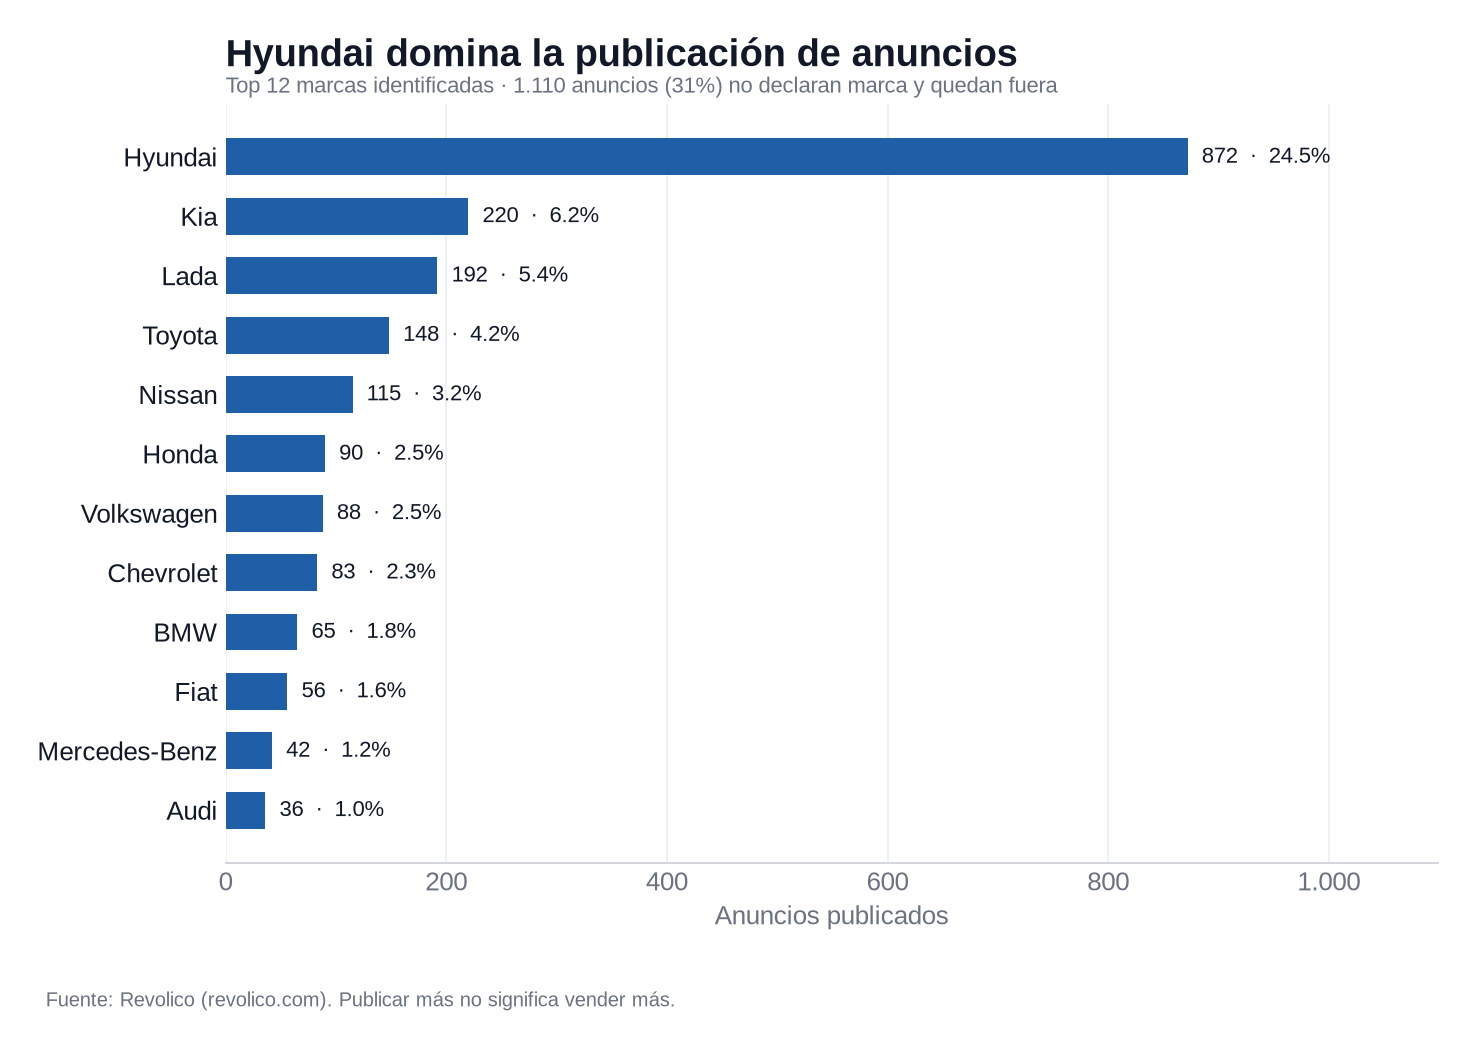

*Figura 4.1. Anuncios por marca en Revolico. Fuente: revolico.com; n=3.566.*

In [3]:
q1 = a["marca"].value_counts().rename_axis("Marca").reset_index(name="Anuncios")
q1["% del total"] = q1["Anuncios"] / len(a) * 100
q1["Marca"] = q1["Marca"].map(etiqueta_marca)
q1_marcas = q1[q1["Marca"] != "No identificada"].copy()
tabla(q1_marcas.head(10), enteros=["Anuncios"], pct=["% del total"], titulo="Tabla 4.1. Anuncios por marca (Q1). Base: 3.566 anuncios.")

no_id = q1[q1["Marca"] == "No identificada"]
print(f"\nSin marca identificada: {fmt_int(no_id['Anuncios'].iloc[0])} anuncios ({fmt_pct(no_id['% del total'].iloc[0])})")
print(f"Hyundai + Kia + Lada: {fmt_pct(q1_marcas.head(3)['% del total'].sum())} del total")

mostrar_figura("a_estructura_concentracion_marca.png", titulo="Figura 4.1. Anuncios por marca en Revolico. Fuente: revolico.com; n=3.566.")

### 4.2 Q2 · ¿Cuál es el promedio de precios por marca?

**Respuesta:** entre las marcas con `n≥30`, las medianas van de **5.500 USD (Fiat, n=51)** a **46.000 USD (BMW, n=33)**. Hyundai, la marca más publicada, tiene una mediana de **29.000 USD** (n=713).

**Por qué mediana y no media aritmética:** la media es sensible a los valores extremos. Por eso la tabla muestra las tres medidas: media, mediana y media recortada al 10%. La mediana es la referencia; la recortada confirma que la conclusión no depende de las colas.

> **Base:** 2.703 anuncios con precio válido. Solo se listan marcas con `n≥30`.

**Tabla 4.2. Precios por marca (Q2). Base: 2.703 anuncios con precio válido; solo n≥30.**

,Marca,n,media,mediana,recortada_10,p25,p75
4,BMW,33,63.091 USD,46.000 USD,56.241 USD,31.000 USD,85.000 USD
14,Dongfeng,32,34.867 USD,35.000 USD,32.498 USD,27.429 USD,35.250 USD
24,Honda,74,32.896 USD,32.250 USD,32.873 USD,26.000 USD,40.000 USD
42,Nissan,106,28.500 USD,30.000 USD,28.482 USD,23.250 USD,32.000 USD
25,Hyundai,713,29.355 USD,29.000 USD,29.261 USD,21.500 USD,37.500 USD
37,Mercedes-Benz,31,41.161 USD,25.000 USD,30.480 USD,22.000 USD,45.000 USD
54,Toyota,127,27.593 USD,24.997 USD,26.961 USD,18.500 USD,38.000 USD
31,Kia,177,21.473 USD,18.000 USD,19.827 USD,16.000 USD,24.000 USD
45,Peugeot,30,11.020 USD,12.000 USD,11.167 USD,7.500 USD,14.000 USD
10,Chevrolet,67,16.514 USD,9.500 USD,15.421 USD,6.000 USD,29.750 USD


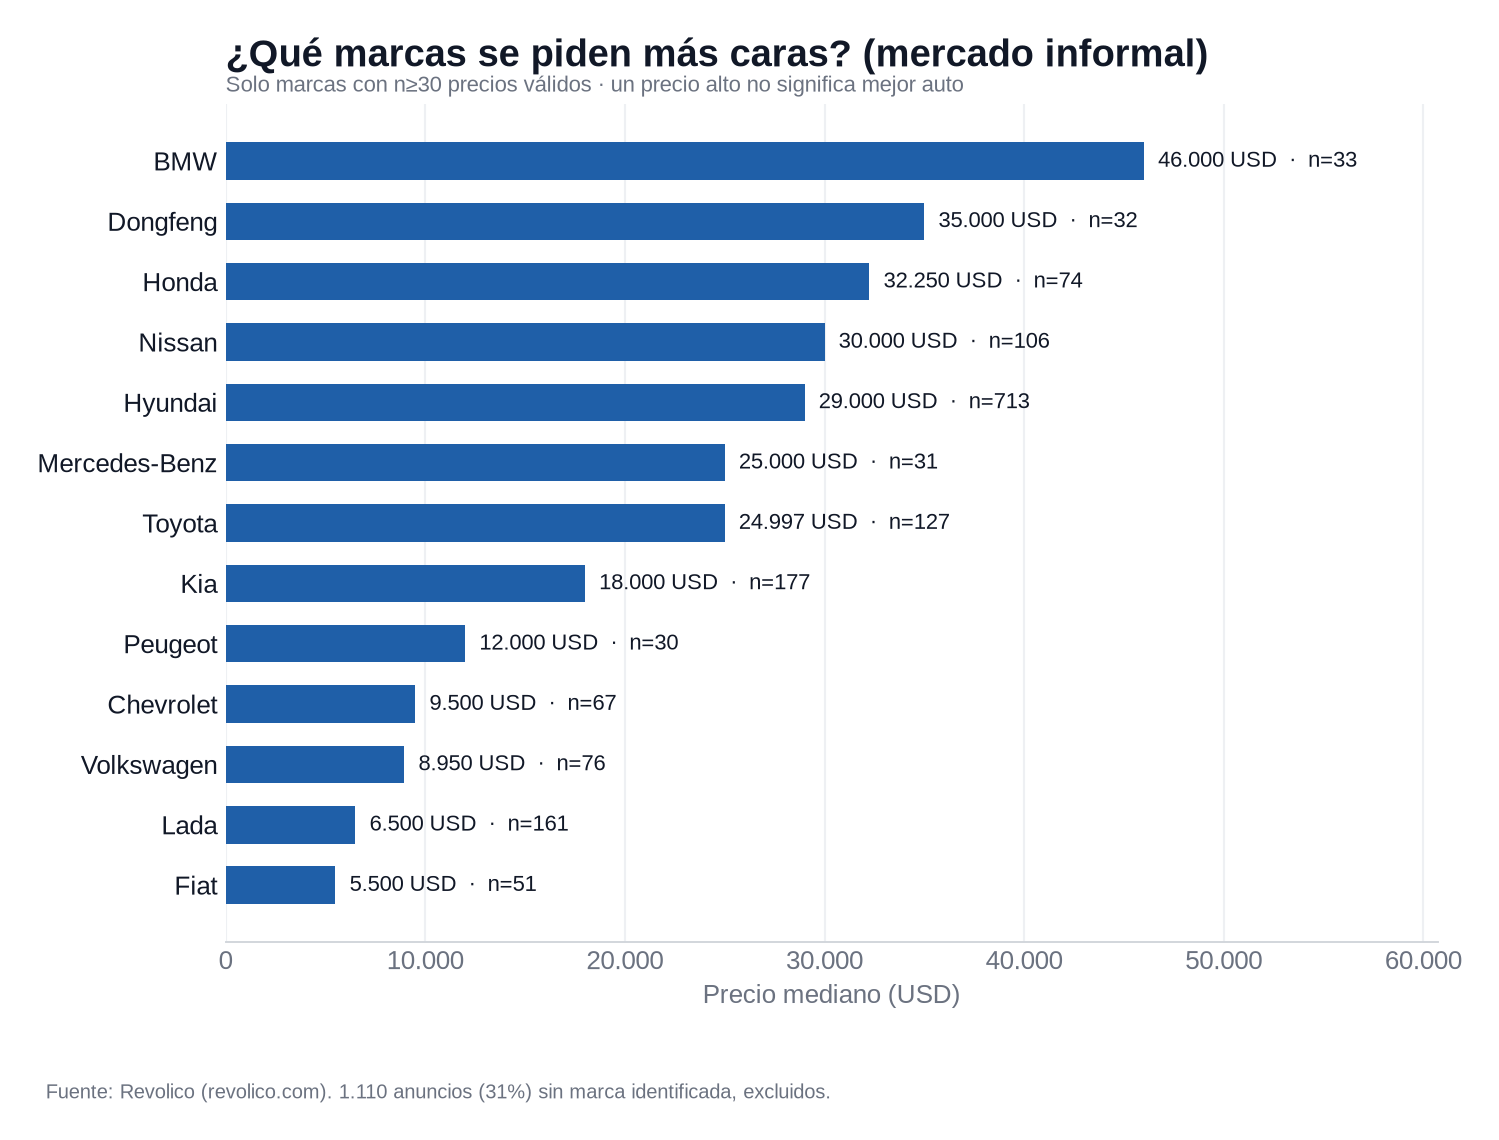

*Figura 4.2. Precio mediano por marca informal (n≥30). Fuente: revolico.com; n=2.703.*

In [4]:
cat = va[va["marca"] != "no identificada"]
q2 = (
    cat.groupby("marca")["precio_usd"]
       .agg(n="size", media="mean", mediana="median",
            p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75))
       .reset_index()
)
q2["recortada_10"] = cat.groupby("marca")["precio_usd"].apply(media_recortada).reindex(q2["marca"]).values
q2 = q2[q2["n"] >= 30].sort_values("mediana", ascending=False)
q2["Marca"] = q2["marca"].map(etiqueta_marca)

tabla(
    q2[["Marca", "n", "media", "mediana", "recortada_10", "p25", "p75"]],
    enteros=["n"], usd=["media", "mediana", "recortada_10", "p25", "p75"],
    titulo="Tabla 4.2. Precios por marca (Q2). Base: 2.703 anuncios con precio válido; solo n≥30."
)

mostrar_figura("03_precio_por_marca_informal.png", titulo="Figura 4.2. Precio mediano por marca informal (n≥30). Fuente: revolico.com; n=2.703.")

### 4.3 Q3 · ¿Existe relación entre el precio y el año de fabricación?

**Respuesta:** sí, una asociación positiva y fuerte en términos monotónicos: **Spearman ρ = 0,65** (n=1.519). La correlación de Pearson es menor (**r = 0,37**, R² = 0,14) porque la relación no es lineal y los precios extremos pesan.

La mediana por década muestra el patrón con más claridad: **12.000 USD** en los 2000, **20.000 USD** en los 2010 y **33.000 USD** en los 2020. En las décadas antiguas hay muy pocos casos (3–26), así que sus medianas son frágiles.

**Cautela:** el año explica parte de la variación, no toda. Kilometraje, estado, versión y marca no están controlados. El coeficiente OLS (583 USD/año) y el robusto de Theil-Sen (1.417 USD/año) difieren; por eso **no se usa un único “precio por año” como predictor**.

**Tabla 4.3. Asociación entre precio y año (Q3).**

,Medida,Valor,Nota
0,n (precio válido y año > 0),1.519,—
1,Pearson r,"0,369",p = 3.8e-50
2,Spearman ρ,"0,653",p = 1.1e-185
3,R² (OLS),"0,136",—
4,Pendiente OLS,583 USD / año,sensible a extremos
5,Pendiente Theil-Sen,1.417 USD / año,IC 95%: 1.300 USD–1.500 USD



Mediana por década:


**Tabla 4.4. Mediana por década (Q3).**

,decada,n,mediana
0,1950,26,5.250 USD
1,1960,5,4.000 USD
2,1970,8,5.000 USD
3,1980,3,2.500 USD
4,1990,16,8.000 USD
5,2000,88,12.000 USD
6,2010,441,20.000 USD
7,2020,932,33.000 USD


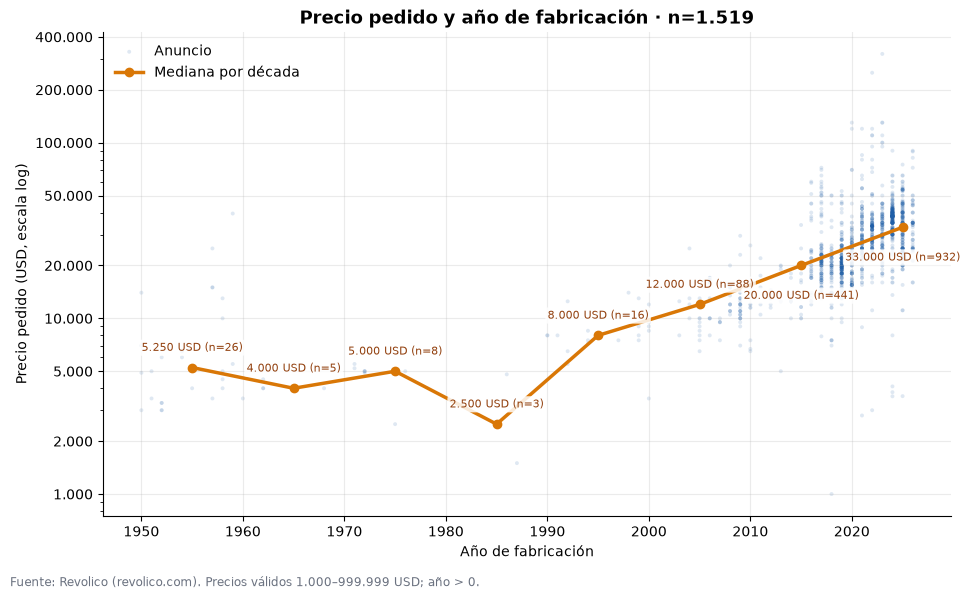

*Figura 4.3. Precio pedido y año de fabricación. Fuente: revolico.com; n=1.519.*

In [5]:
d = va[va["anio"] > 0].copy()
r_pearson, p_pearson = stats.pearsonr(d["anio"], d["precio_usd"])
r_spearman, p_spearman = stats.spearmanr(d["anio"], d["precio_usd"])
slope, intercept = np.polyfit(d["anio"], d["precio_usd"], 1)
r2 = r_pearson ** 2
theil = stats.theilslopes(d["precio_usd"], d["anio"])

resumen_q3 = pd.DataFrame([
    ("n (precio válido y año > 0)", fmt_int(len(d)), "—"),
    ("Pearson r", f"{r_pearson:.3f}".replace(".", ","), f"p = {p_pearson:.1e}"),
    ("Spearman ρ", f"{r_spearman:.3f}".replace(".", ","), f"p = {p_spearman:.1e}"),
    ("R² (OLS)", f"{r2:.3f}".replace(".", ","), "—"),
    ("Pendiente OLS", fmt_usd(slope) + " / año", "sensible a extremos"),
    ("Pendiente Theil-Sen", fmt_usd(theil.slope) + " / año", f"IC 95%: {fmt_usd(theil.low_slope)}–{fmt_usd(theil.high_slope)}"),
], columns=["Medida", "Valor", "Nota"])
display(Markdown("**Tabla 4.3. Asociación entre precio y año (Q3).**"))
display(resumen_q3)

dec = (
    d.assign(decada=(d["anio"] // 10) * 10)
     .groupby("decada")["precio_usd"]
     .agg(n="size", mediana="median")
     .reset_index()
)
print("\nMediana por década:")
tabla(dec, enteros=["n"], usd=["mediana"], titulo="Tabla 4.4. Mediana por década (Q3).")

# Figura generada desde los datos: dispersión + mediana por década
fig, ax = plt.subplots(figsize=(9.8, 5.8))
ax.scatter(d["anio"], d["precio_usd"], s=8, alpha=0.14, color="#1F5FA8", edgecolors="none", label="Anuncio")
ax.plot(dec["decada"] + 5, dec["mediana"], color="#D97706", marker="o", lw=2.5, label="Mediana por década")
for pos, fila in enumerate(dec.itertuples()):
    dy = -24 if pos >= len(dec) - 2 else 12
    ax.annotate(
        f"{fmt_usd(fila.mediana)} (n={fila.n})",
        (fila.decada + 5, fila.mediana),
        xytext=(0, dy), textcoords="offset points", ha="center", fontsize=8,
        color="#92400e",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
    )
ax.set_yscale("log")
ax.set_yticks([1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 200_000, 400_000])
ax.get_yaxis().set_major_formatter(mticker.FuncFormatter(lambda x, _: fmt_int(x)))
ax.set_xlabel("Año de fabricación")
ax.set_ylabel("Precio pedido (USD, escala log)")
ax.set_title(f"Precio pedido y año de fabricación · n={fmt_int(len(d))}")
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, -0.02, "Fuente: Revolico (revolico.com). Precios válidos 1.000–999.999 USD; año > 0.", fontsize=8.5, color="#6B7280")
plt.tight_layout()
plt.show()
display(Markdown("*Figura 4.3. Precio pedido y año de fabricación. Fuente: revolico.com; n=1.519.*"))

### 4.4 Q4 · ¿Cuál es la marca con los precios más elevados?

**Respuesta:** entre las marcas con muestra suficiente (`n≥30`), **BMW** tiene la mediana más alta (**46.000 USD**, n=33), seguida de **Dongfeng** (35.000, n=32) y **Honda** (32.250, n=74).

**Cuidado con las muestras pequeñas:** **Foton** aparece con 50.000 USD, pero solo n=10; no se usa para ordenar. El problema es aún más claro con **Cadillac (85.000 USD, n=6)**, **Hino (65.000, n=1)** o **GMC (65.000, n=3)**: una mediana alta con `n<10` es una anécdota, no un hallazgo.

In [6]:
base_m = (
    va[va["marca"] != "no identificada"]
      .groupby("marca")["precio_usd"]
      .agg(n="size", mediana="median")
      .reset_index()
)
base_m["Marca"] = base_m["marca"].map(etiqueta_marca)

q4 = base_m[base_m["n"] >= 30].sort_values("mediana", ascending=False).head(10)
print("Marcas con n≥30, ordenadas por mediana:")
tabla(q4[["Marca", "n", "mediana"]], enteros=["n"], usd=["mediana"], titulo="Tabla 4.5. Marcas con n≥30 por mediana (Q4).")

q4_small = base_m[base_m["n"] < 30].sort_values("mediana", ascending=False).head(5)
print("\nMarcas con n<30 y mediana alta (no comparables):")
tabla(q4_small[["Marca", "n", "mediana"]], enteros=["n"], usd=["mediana"], titulo="Tabla 4.6. Marcas con n<30 y mediana alta: no comparables.")

Marcas con n≥30, ordenadas por mediana:


**Tabla 4.5. Marcas con n≥30 por mediana (Q4).**

,Marca,n,mediana
4,BMW,33,46.000 USD
14,Dongfeng,32,35.000 USD
24,Honda,74,32.250 USD
42,Nissan,106,30.000 USD
25,Hyundai,713,29.000 USD
37,Mercedes-Benz,31,25.000 USD
54,Toyota,127,24.997 USD
31,Kia,177,18.000 USD
45,Peugeot,30,12.000 USD
10,Chevrolet,67,9.500 USD



Marcas con n<30 y mediana alta (no comparables):


**Tabla 4.6. Marcas con n<30 y mediana alta: no comparables.**

,Marca,n,mediana
7,Cadillac,6,85.000 USD
23,Hino,1,65.000 USD
21,GMC,3,65.000 USD
56,Volvo,3,56.000 USD
17,Foton,10,50.000 USD


### 4.5 Q5 · ¿Qué proporción de anuncios corresponde a clásicos y modernos?

**Respuesta:** de los **1.821 anuncios que declaran año**, **69 son clásicos** (<2000) y **1.752 modernos** (≥2000): **3,8% vs. 96,2%**. Pero **1.745 anuncios (48,9%) no declaran año**, así que la composición real del parque ofertado es una incógnita.

**Lectura:** el mercado published se ve moderno, pero esa imagen está condicionada por quién declara el año. Los clásicos que sí se declaran son pocos y suelen tener precios bajos, aunque con excepciones.

**Tabla 4.7. Composición por año declarado (Q5).**

,Categoría,n,% del total,% de los que declaran año
0,Clásicos (<2000),69,"1,9 %","3,8 %"
1,Modernos (≥2000),1.752,"49,1 %","96,2 %"
2,Sin año declarado,1.745,"48,9 %",—


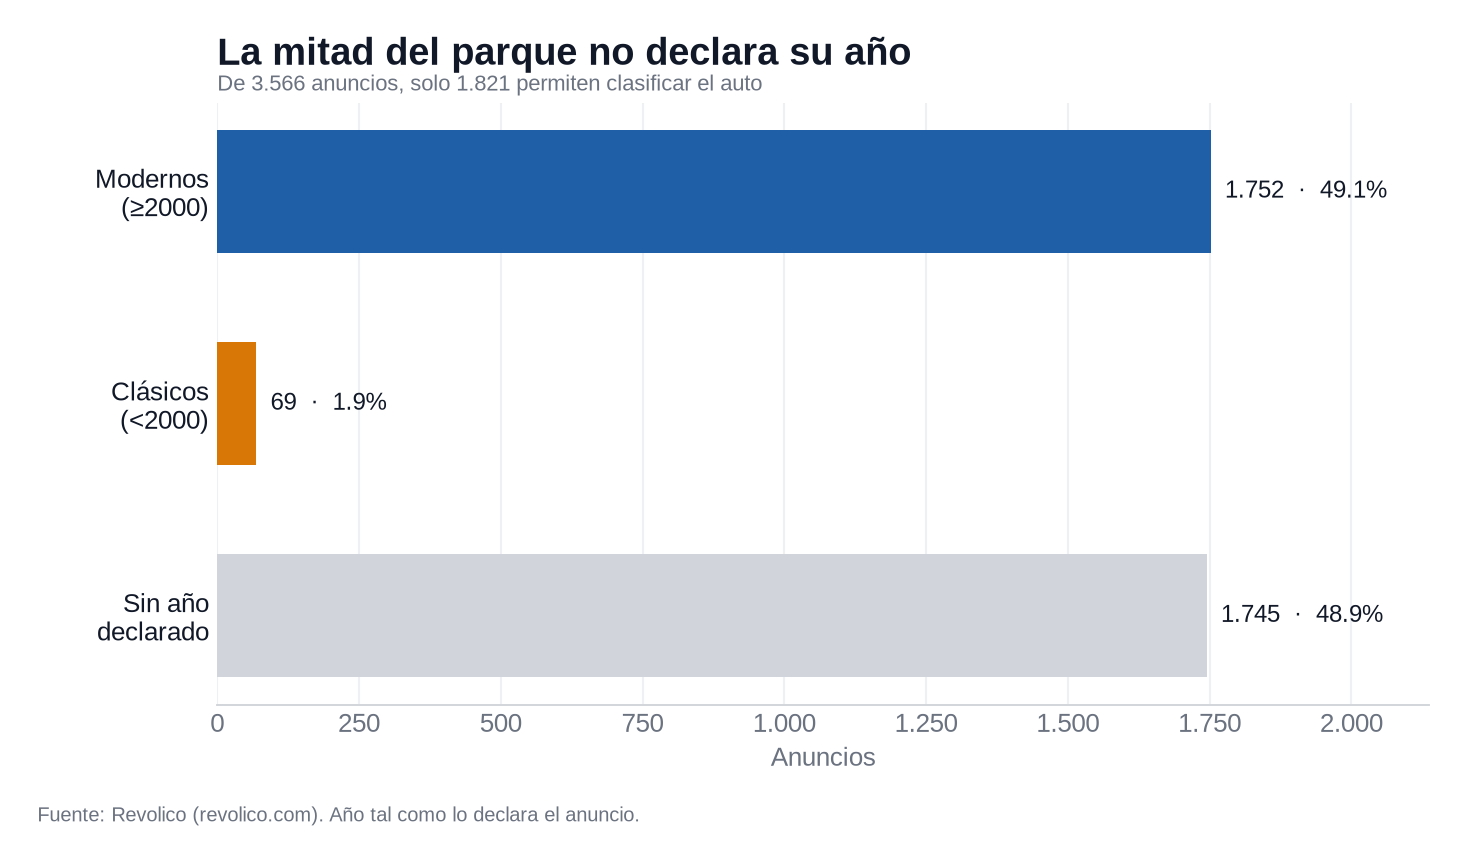

*Figura 4.4. Composición por año declarado. Fuente: revolico.com; n=3.566.*

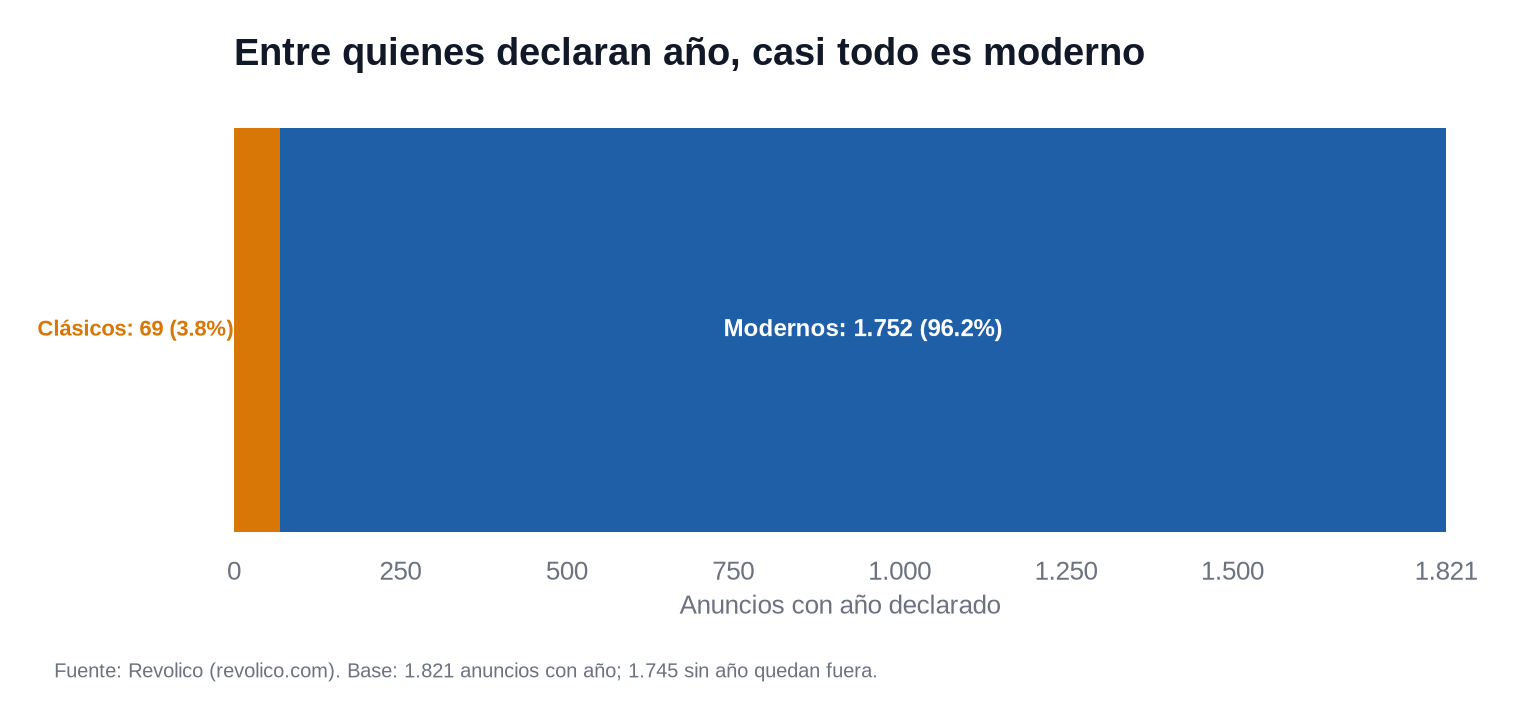

*Figura 4.5. Proporción entre los 1.821 anuncios con año. Fuente: revolico.com.*

In [7]:
con = a[a["anio"] > 0]
clasicos = int((con["anio"] < 2000).sum())
modernos = int((con["anio"] >= 2000).sum())
sin_anio = int((a["anio"] == 0).sum())

q5 = pd.DataFrame([
    ("Clásicos (<2000)", clasicos, clasicos / len(a) * 100, clasicos / len(con) * 100),
    ("Modernos (≥2000)", modernos, modernos / len(a) * 100, modernos / len(con) * 100),
    ("Sin año declarado", sin_anio, sin_anio / len(a) * 100, np.nan),
], columns=["Categoría", "n", "% del total", "% de los que declaran año"])
tabla(q5, enteros=["n"], pct=["% del total", "% de los que declaran año"], titulo="Tabla 4.7. Composición por año declarado (Q5).")

mostrar_figura("q5_clasicos_vs_modernos_conteo.png", titulo="Figura 4.4. Composición por año declarado. Fuente: revolico.com; n=3.566.")
mostrar_figura("q5_clasicos_vs_modernos_proporcion.png", titulo="Figura 4.5. Proporción entre los 1.821 anuncios con año. Fuente: revolico.com.")

### 4.6 Q6 · ¿Cuál es la diferencia entre el mercado formal y el informal?

**Respuesta:** la mediana informal es **22.000 USD** (n=2.703) y la formal **32.699 USD** (83 modelos de catálogo): una brecha de **10.699 USD**. La media recortada confirma la dirección: 22.196 vs. 34.083 USD.

Seis marcas aparecen en ambos canales con al menos **10 anuncios informales** y presencia en el catálogo formal. **El catálogo no es una muestra:** es la lista de precios de cada entidad y no permite estimar ventas. Su cobertura varía: Toyota tiene 1 modelo, Nissan 3, Mercedes-Benz 5, MG 8, Foton 15 y Dongfeng 27.

| Marca | Informal (n) | Formal (modelos) | Diferencia |
|---|---:|---:|---:|
| Dongfeng | 35.000 USD (32) | 32.383 USD (27) | +2.617 USD |
| Foton | 50.000 USD (10) | 44.709 USD (15) | +5.291 USD |
| MG | 24.000 USD (19) | 22.896 USD (8) | +1.104 USD |
| Toyota | 24.997 USD (127) | 22.380 USD (1) | +2.617 USD |
| Nissan | 30.000 USD (106) | 35.000 USD (3) | −5.000 USD |
| Mercedes-Benz | 25.000 USD (31) | 72.722 USD (5) | −47.722 USD |

**Lectura:** la dirección de la brecha **no es uniforme**. El informal pide más en Dongfeng, Foton, MG y Toyota; el formal es más caro en Nissan y, sobre todo, en Mercedes-Benz. Esta última brecha refleja un catálogo de autos nuevos de gama alta, no una estimación de ventas. La brecha global (10.699 USD) y las brechas por marca no son la misma cosa y no deben confundirse.


**Tabla 4.8. Brecha formal-informal (Q6). Registros: anuncios informales / modelos de catálogo.**

,Canal,Registros,Mediana,Media recortada 10%,P25,P75
0,Informal (Revolico),2.703,22.000 USD,22.196 USD,10.250 USD,34.000 USD
1,Formal (catálogo),83,32.699 USD,34.083 USD,26.837 USD,42.514 USD


Brecha de medianas: 10.699 USD


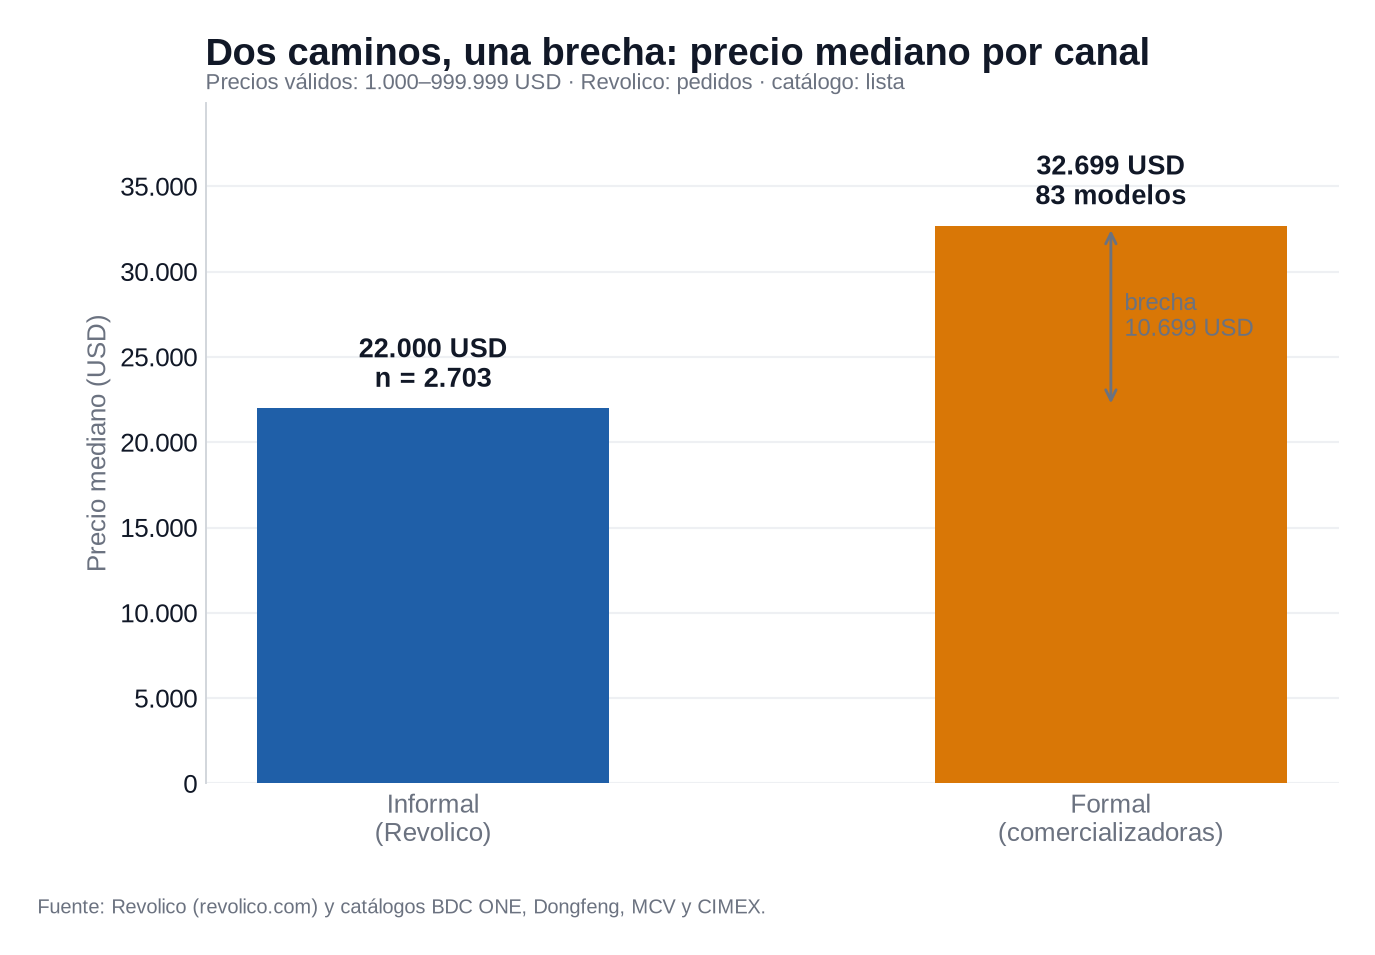

*Figura 4.6. Brecha de medianas formal-informal. Fuente: revolico.com y catálogos formales; 2.703 anuncios y 83 modelos.*


Marcas con ≥10 anuncios informales y presencia en el catálogo formal:


**Tabla 4.9. Marcas con ≥10 anuncios informales y presencia en catálogo formal (Q6).**

,Marca,n_inf,med_inf,modelos,med_form,Diferencia
0,Dongfeng,32,35.000 USD,27,32.383 USD,2.617 USD
1,Foton,10,50.000 USD,15,44.709 USD,5.291 USD
3,MG,19,24.000 USD,8,22.896 USD,1.104 USD
2,Mercedes-Benz,31,25.000 USD,5,72.722 USD,-47.722 USD
4,Nissan,106,30.000 USD,3,35.000 USD,-5.000 USD
5,Toyota,127,24.997 USD,1,22.380 USD,2.617 USD


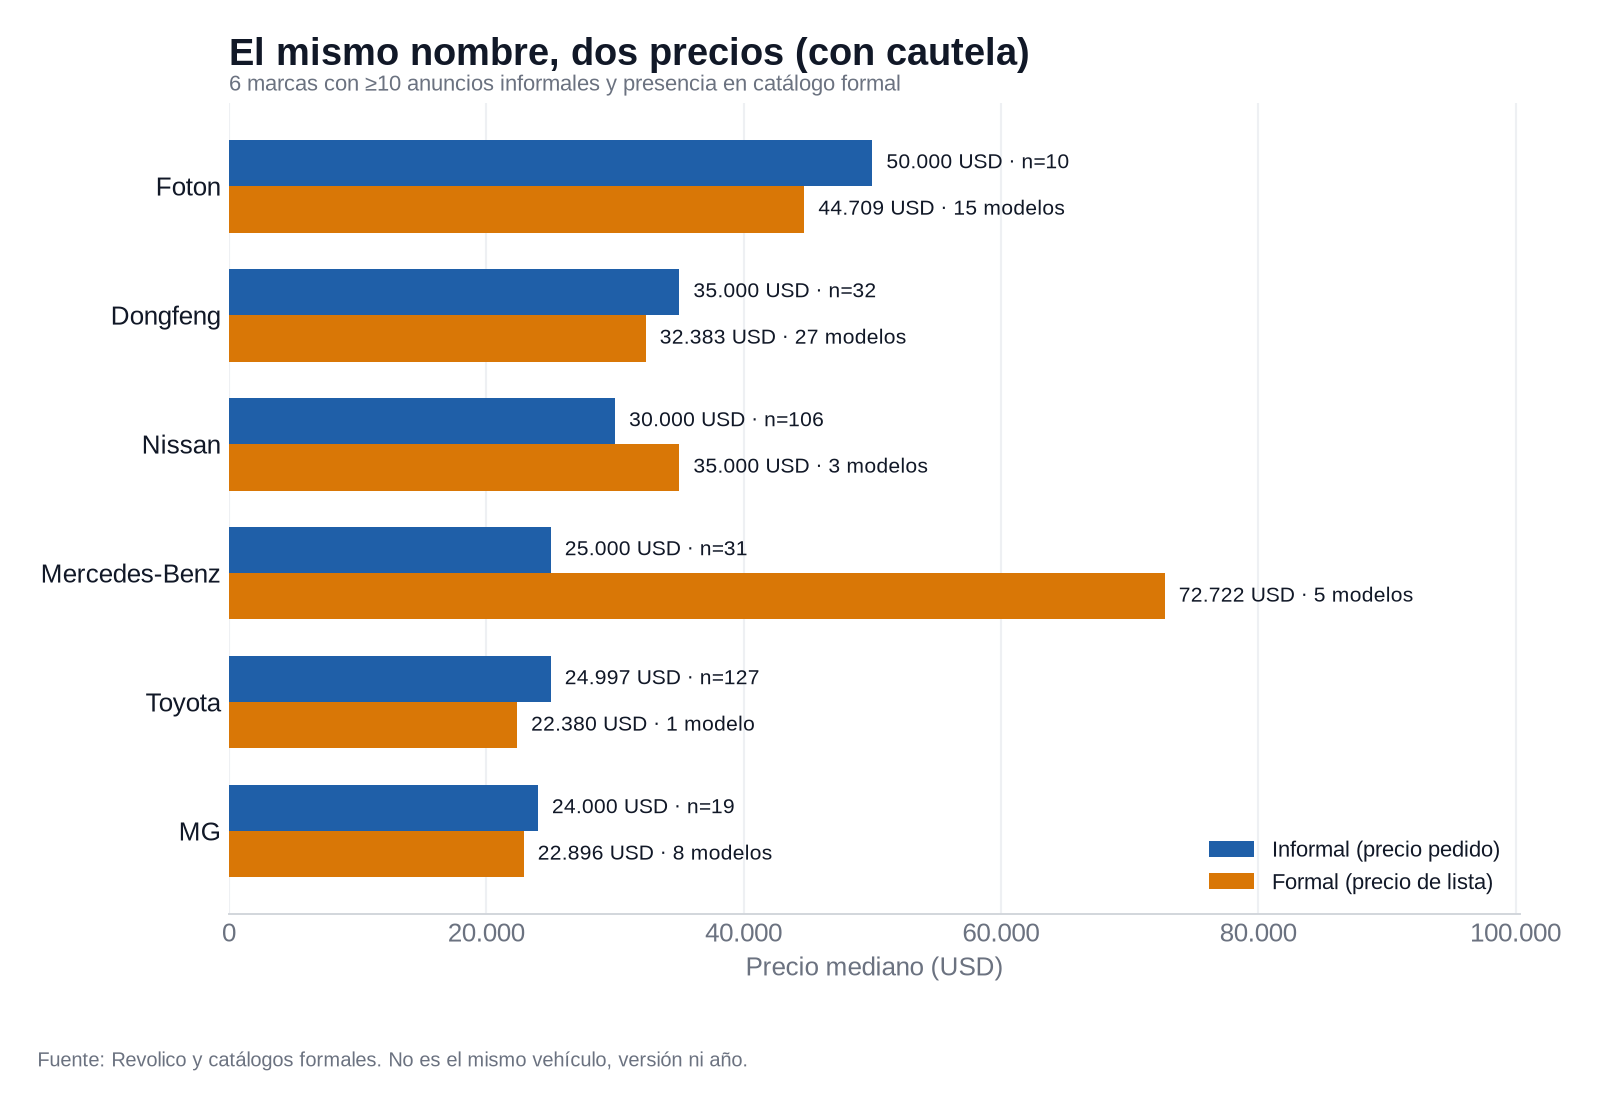

*Figura 4.7. Comparación por marca: 6 marcas con ≥10 anuncios informales y presencia en catálogo. Fuente: revolico.com y catálogos formales.*

In [8]:
q6 = pd.DataFrame({
    "Canal": ["Informal (Revolico)", "Formal (catálogo)"],
    "Registros": [len(va), len(c)],
    "Mediana": [va["precio_usd"].median(), c["precio_usd"].median()],
    "Media recortada 10%": [media_recortada(va["precio_usd"]), media_recortada(c["precio_usd"])],
    "P25": [va["precio_usd"].quantile(0.25), c["precio_usd"].quantile(0.25)],
    "P75": [va["precio_usd"].quantile(0.75), c["precio_usd"].quantile(0.75)],
})
tabla(q6, enteros=["Registros"], usd=["Mediana", "Media recortada 10%", "P25", "P75"],
      titulo="Tabla 4.8. Brecha formal-informal (Q6). Registros: anuncios informales / modelos de catálogo.")
print(f"Brecha de medianas: {fmt_usd(q6.loc[1, 'Mediana'] - q6.loc[0, 'Mediana'])}")
mostrar_figura("01_brecha_formal_vs_informal.png",
               titulo="Figura 4.6. Brecha de medianas formal-informal. Fuente: revolico.com y catálogos formales; 2.703 anuncios y 83 modelos.")

inf = va[va["marca"] != "no identificada"].groupby("marca")["precio_usd"].agg(n_inf="size", med_inf="median")
form = c[~c["marca_web"].isin(["microbus", "pickup"])].groupby("marca_web")["precio_usd"].agg(modelos="size", med_form="median")
comp = inf.join(form, how="inner").query("n_inf >= 10").reset_index()
comp["Marca"] = comp["marca"].map(etiqueta_marca)
comp["Diferencia"] = comp["med_inf"] - comp["med_form"]
comp = comp.sort_values("Marca")
print("\nMarcas con ≥10 anuncios informales y presencia en el catálogo formal:")
tabla(comp[["Marca", "n_inf", "med_inf", "modelos", "med_form", "Diferencia"]],
      enteros=["n_inf", "modelos"], usd=["med_inf", "med_form", "Diferencia"],
      titulo="Tabla 4.9. Marcas con ≥10 anuncios informales y presencia en catálogo formal (Q6).")
mostrar_figura("04_comparacion_formal_vs_informal_por_marca.png",
               titulo="Figura 4.7. Comparación por marca: 6 marcas con ≥10 anuncios informales y presencia en catálogo. Fuente: revolico.com y catálogos formales.")


#### 4.6.1 Composición del catálogo formal

Antes de comparar, conviene describir qué hay en el canal formal. El catálogo tiene **83 modelos**, **4 entidades** y **11 marcas** (después de agrupar “Changan Deepal” en Changan). Los precios de lista van de **10.645 USD** (Bestune Pony) a **79.125 USD** (Mercedes-Benz GLC Coupé).

**No se ordenan las entidades por precio medio:** venden canastas distintas. BDC ONE ofrece MG y Maxus; Dongfeng vende Dongfeng; MCV comercializa Mercedes-Benz, Changan, BAIC, Foton, DFSK y Bestune; CIMEX, Nissan y Toyota —más dos ítems Microbús/Pickup que no se tratan como marcas—. Comparar sus medianas sería comparar productos diferentes. La tabla cuenta marcas normalizadas (`marca_web`); “Changan Deepal” se agrupa en Changan.

Entidades del catálogo formal (ordenadas por modelos, no por precio):


**Tabla 4.10. Entidades del catálogo formal (ordenadas por modelos, no por precio).**

,entidad,modelos,marcas,min,max
3,MCV Comercial S.A.,37,6,10.645 USD,79.125 USD
2,DONGFENG CUBA,27,1,17.816 USD,48.071 USD
0,BDC ONE,13,2,16.639 USD,35.272 USD
1,CIMEX,6,4,22.380 USD,44.950 USD



Marcas del catálogo formal (sin Microbús/Pickup):


**Tabla 4.11. Marcas del catálogo formal (sin Microbús/Pickup).**

,Marca,modelos,mediana
0,BAIC,4,45.493 USD
1,Bestune,4,29.468 USD
2,Changan,4,30.198 USD
3,DFSK,5,28.013 USD
4,Dongfeng,27,32.383 USD
5,Foton,15,44.709 USD
6,MAXUS,5,24.592 USD
7,Mercedes-Benz,5,72.722 USD
8,MG,8,22.896 USD
9,Nissan,3,35.000 USD


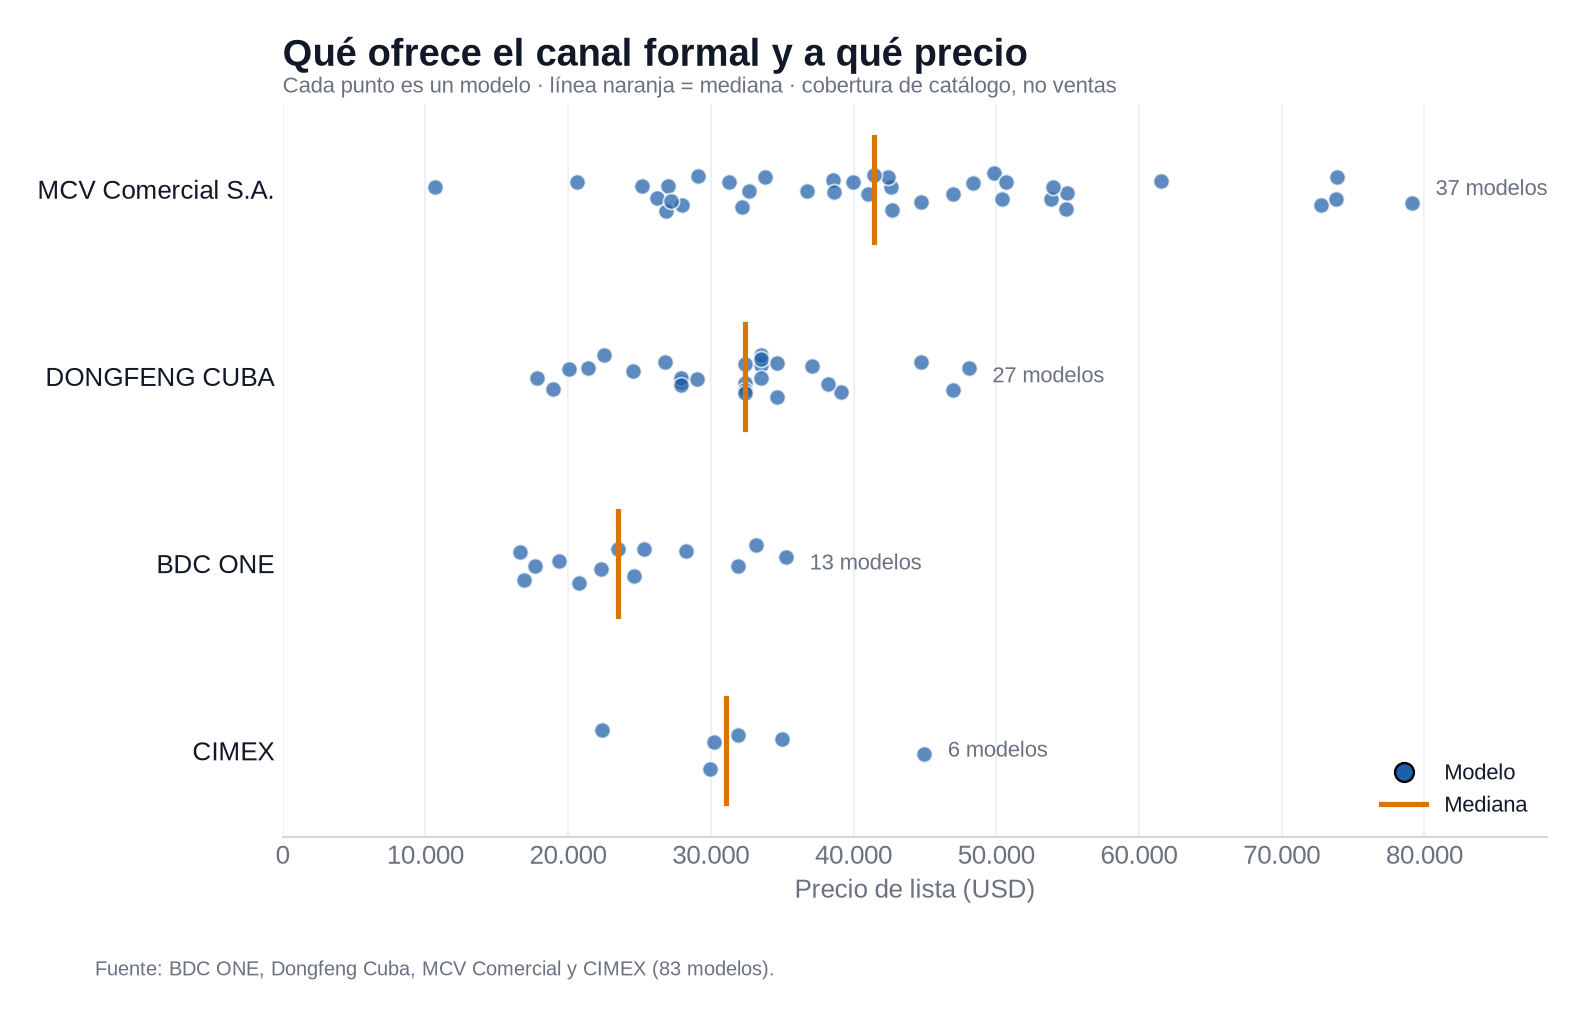

*Figura 4.8. Catálogo formal: precios por entidad (cada punto = un modelo). Fuente: BDC ONE, Dongfeng, MCV y CIMEX; 83 modelos.*

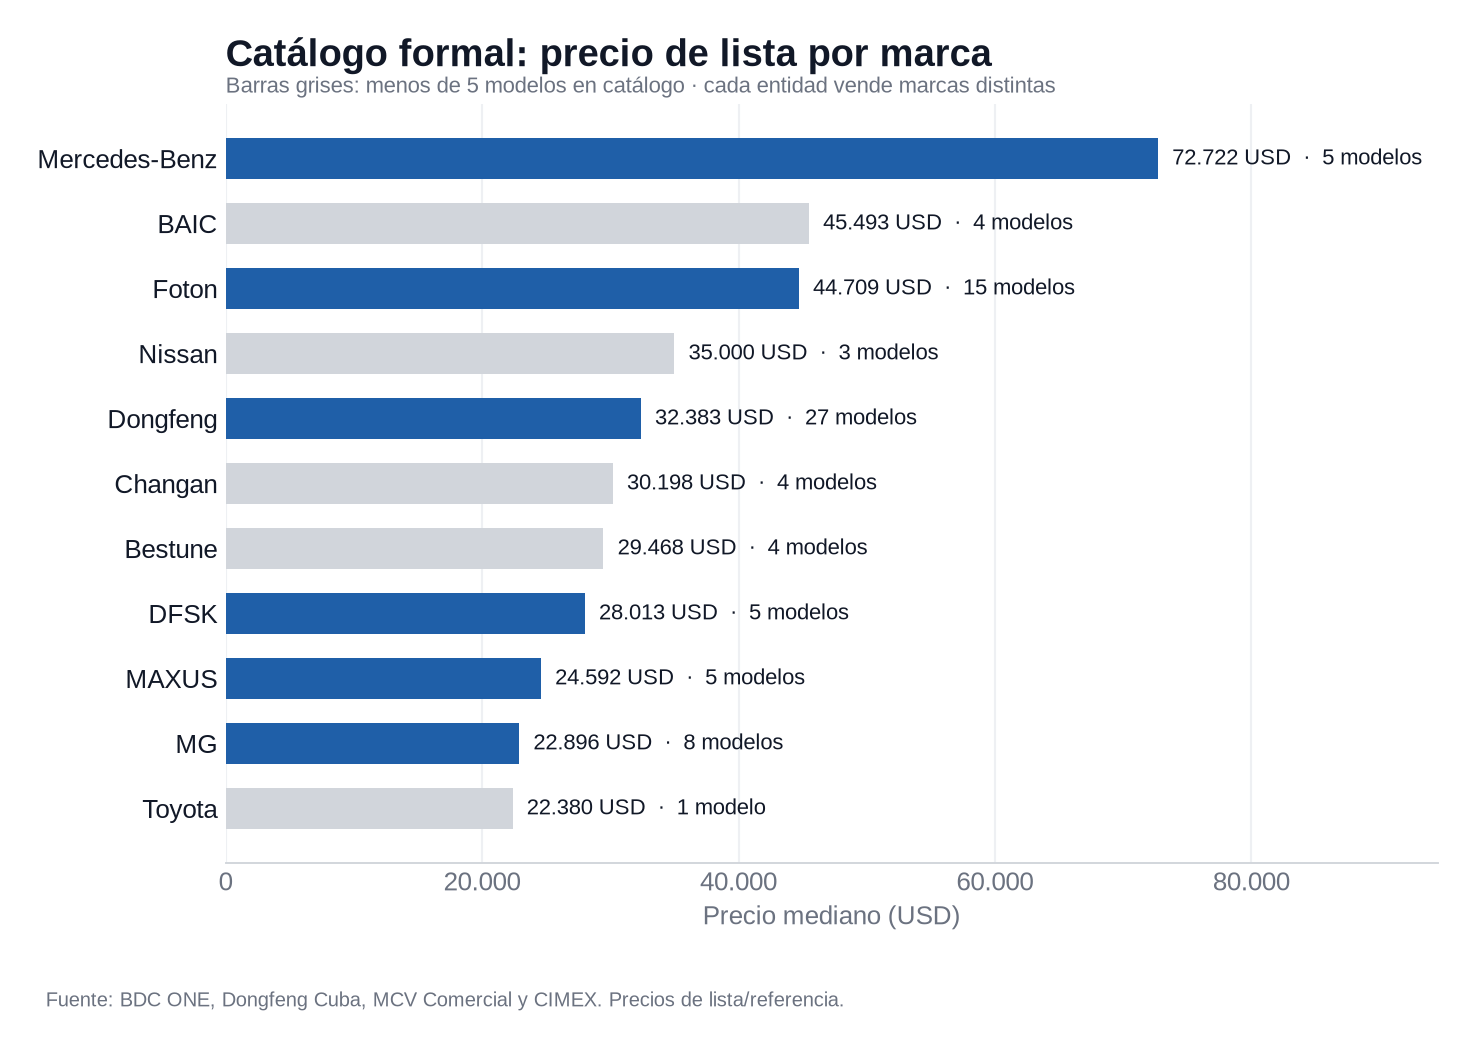

*Figura 4.9. Precio mediano por marca formal. Fuente: catálogos; 83 modelos. Las barras grises indican menos de 5 modelos de catálogo.*

In [9]:
ent = (
    c.groupby("entidad")
     .agg(modelos=("precio_usd", "size"), marcas=("marca_web", "nunique"),
          min=("precio_usd", "min"), max=("precio_usd", "max"))
     .reset_index()
     .sort_values("modelos", ascending=False)
)
print("Entidades del catálogo formal (ordenadas por modelos, no por precio):")
tabla(ent, enteros=["modelos", "marcas"], usd=["min", "max"],
      titulo="Tabla 4.10. Entidades del catálogo formal (ordenadas por modelos, no por precio).")

marcas_form = (
    c[~c["marca_web"].isin(["microbus", "pickup"])]
     .groupby("marca_web")["precio_usd"]
     .agg(modelos="size", mediana="median")
     .reset_index()
     .sort_values("marca_web")
)
marcas_form["Marca"] = marcas_form["marca_web"].map(etiqueta_marca)
print("\nMarcas del catálogo formal (sin Microbús/Pickup):")
tabla(marcas_form[["Marca", "modelos", "mediana"]], enteros=["modelos"], usd=["mediana"],
      titulo="Tabla 4.11. Marcas del catálogo formal (sin Microbús/Pickup).")

mostrar_figura("07_catalogo_formal_por_entidad.png",
               titulo="Figura 4.8. Catálogo formal: precios por entidad (cada punto = un modelo). Fuente: BDC ONE, Dongfeng, MCV y CIMEX; 83 modelos.")
mostrar_figura("03_precio_por_marca_formal.png",
               titulo="Figura 4.9. Precio mediano por marca formal. Fuente: catálogos; 83 modelos. Las barras grises indican menos de 5 modelos de catálogo.")


### 4.7 Q7 · ¿Cuál es el municipio con mayor índice de publicaciones?

**Respuesta:** **Playa** concentra **1.002 anuncios** (28,1%). Le siguen Centro Habana (472; 13,2%), Plaza (360; 10,1%), Diez de Octubre (330; 9,3%) y Arroyo Naranjo (284; 8,0%). Playa + Centro Habana + Plaza reúnen el **51,4%**.

**Lectura:** la concentración es una pista sobre dónde se publica, no sobre dónde hay más autos disponibles. Dos anuncios no tienen municipio y quedan fuera de la tabla territorial.

**Tabla 4.12. Anuncios por municipio (Q7). Base: 3.566.**

,Municipio,Anuncios,% del total
0,Playa,1.002,"28,1 %"
1,Centro Habana,472,"13,2 %"
2,Plaza,360,"10,1 %"
3,Diez de Octubre,330,"9,3 %"
4,Arroyo Naranjo,284,"8,0 %"
5,Habana del Este,180,"5,0 %"
6,Cerro,174,"4,9 %"
7,Boyeros,174,"4,9 %"
8,La Lisa,126,"3,5 %"
9,Marianao,122,"3,4 %"


Top 3: 51,4 % del total


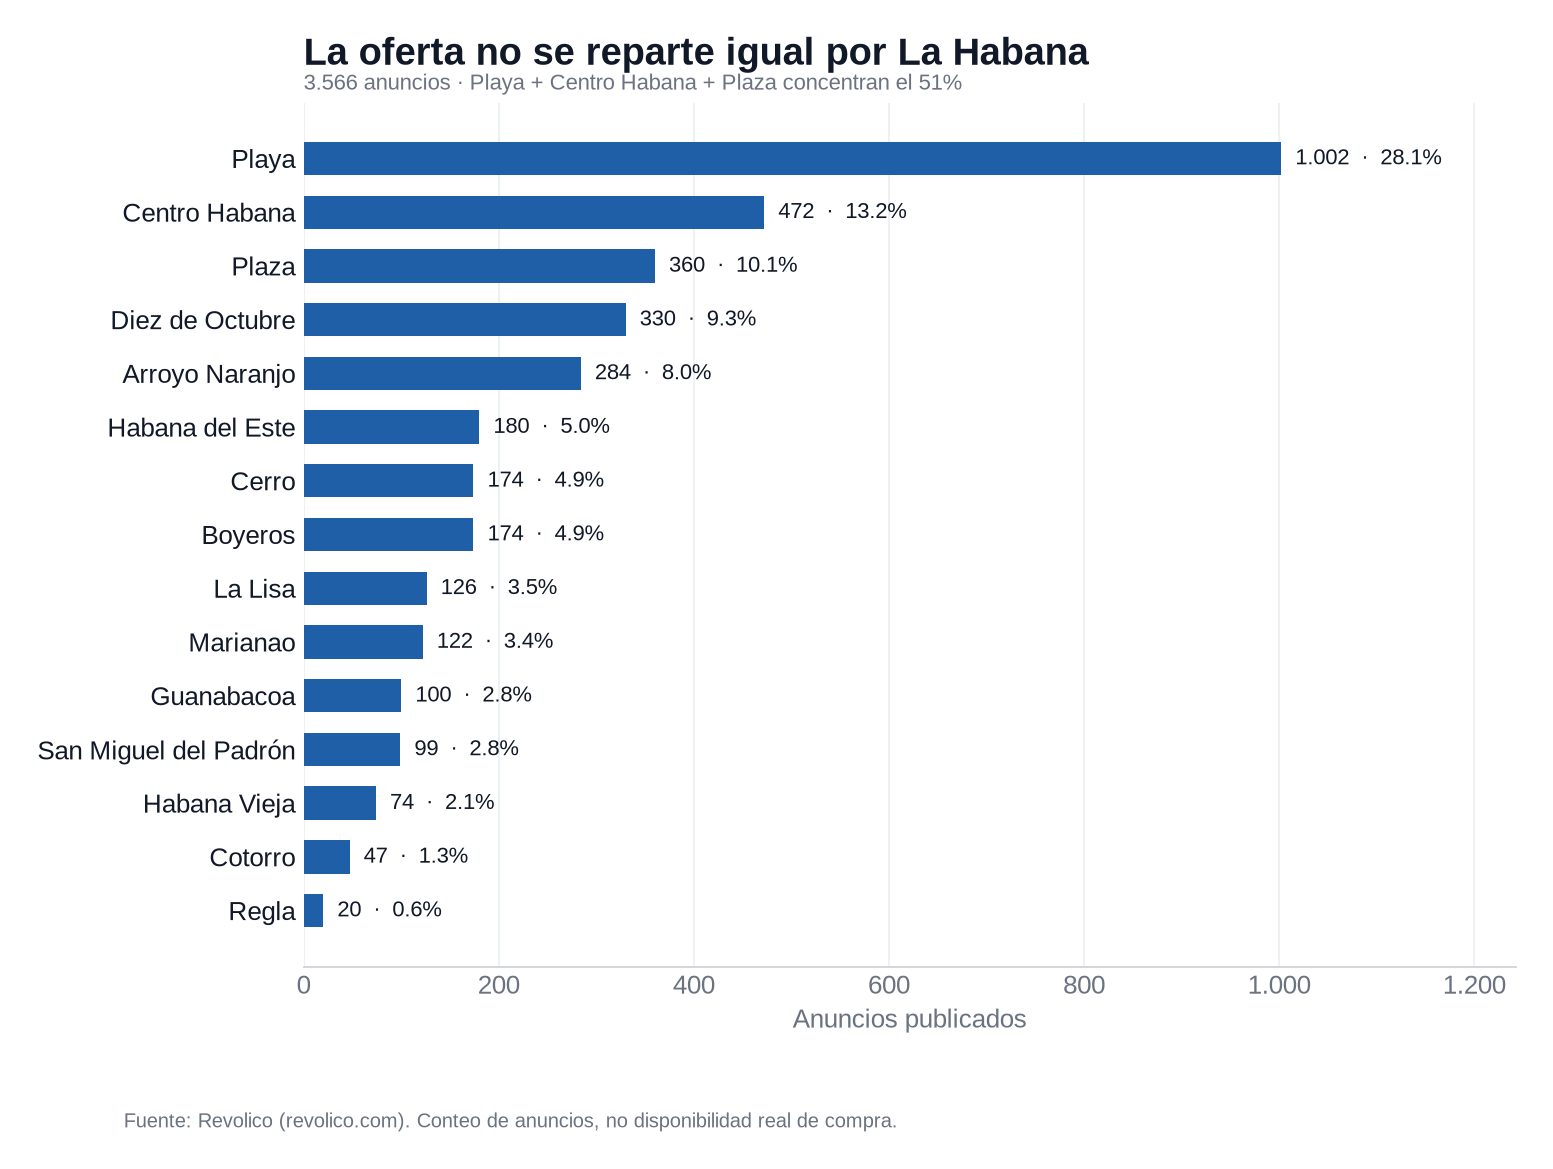

*Figura 4.10. Anuncios por municipio. Fuente: revolico.com; n=3.566.*

In [10]:
q7 = a["municipio"].value_counts().rename_axis("Municipio").reset_index(name="Anuncios")
q7["% del total"] = q7["Anuncios"] / len(a) * 100
q7["Municipio"] = q7["Municipio"].map(etiqueta_municipio)
tabla(q7, enteros=["Anuncios"], pct=["% del total"], titulo="Tabla 4.12. Anuncios por municipio (Q7). Base: 3.566.")
print(f"Top 3: {fmt_pct(q7.head(3)['% del total'].sum())} del total")
mostrar_figura("a_estructura_concentracion_municipio.png", titulo="Figura 4.10. Anuncios por municipio. Fuente: revolico.com; n=3.566.")

### 4.8 Q8 · ¿Existe relación entre el municipio y el precio de venta?

**Respuesta:** sí hay diferencias descriptivas. Entre los municipios con `n≥30`, la mediana va de **13.000 USD (La Lisa, n=96)** a **28.000 USD (Arroyo Naranjo, n=223)**: poco más del doble (2,15×). Marianao queda en **16.000 USD** (n=81).

La prueba de Kruskal-Wallis detecta diferencias estadísticamente significativas (H=146,3; p≈1,15e-24), pero **eso no implica causalidad territorial**: los municipios difieren en el mix de marcas, modelos, años y estado. **Regla (n=15) y el grupo sin municipio (n=1)** quedan fuera del ranking por `n<30`.

**Tabla 4.13. Precio por municipio con n≥30 (Q8). Base: 2.703.**

,Municipio,n,mediana,recortada_10,p25,p75
0,Arroyo Naranjo,223,28.000 USD,27.461 USD,19.500 USD,37.500 USD
8,Habana Vieja,50,26.800 USD,26.956 USD,17.625 USD,35.750 USD
2,Centro Habana,339,26.000 USD,25.669 USD,16.000 USD,35.000 USD
11,Playa,763,24.000 USD,24.793 USD,15.000 USD,35.000 USD
14,San Miguel del Padrón,65,22.000 USD,22.061 USD,11.111 USD,32.000 USD
1,Boyeros,147,20.000 USD,20.673 USD,8.500 USD,34.950 USD
7,Habana del Este,157,19.500 USD,20.174 USD,10.000 USD,31.600 USD
6,Guanabacoa,80,19.000 USD,19.459 USD,8.375 USD,31.250 USD
3,Cerro,132,18.000 USD,19.300 USD,8.000 USD,32.500 USD
5,Diez de Octubre,243,17.000 USD,17.893 USD,7.000 USD,30.000 USD



Municipios excluidos por n<30:


**Tabla 4.14. Municipios excluidos por n<30.**

,Municipio,n,mediana
13,Regla,15,11.000 USD
15,Sin Dato,1,38.500 USD



Kruskal-Wallis: H=146.3, p=1.15e-24 · 14 municipios con n≥30


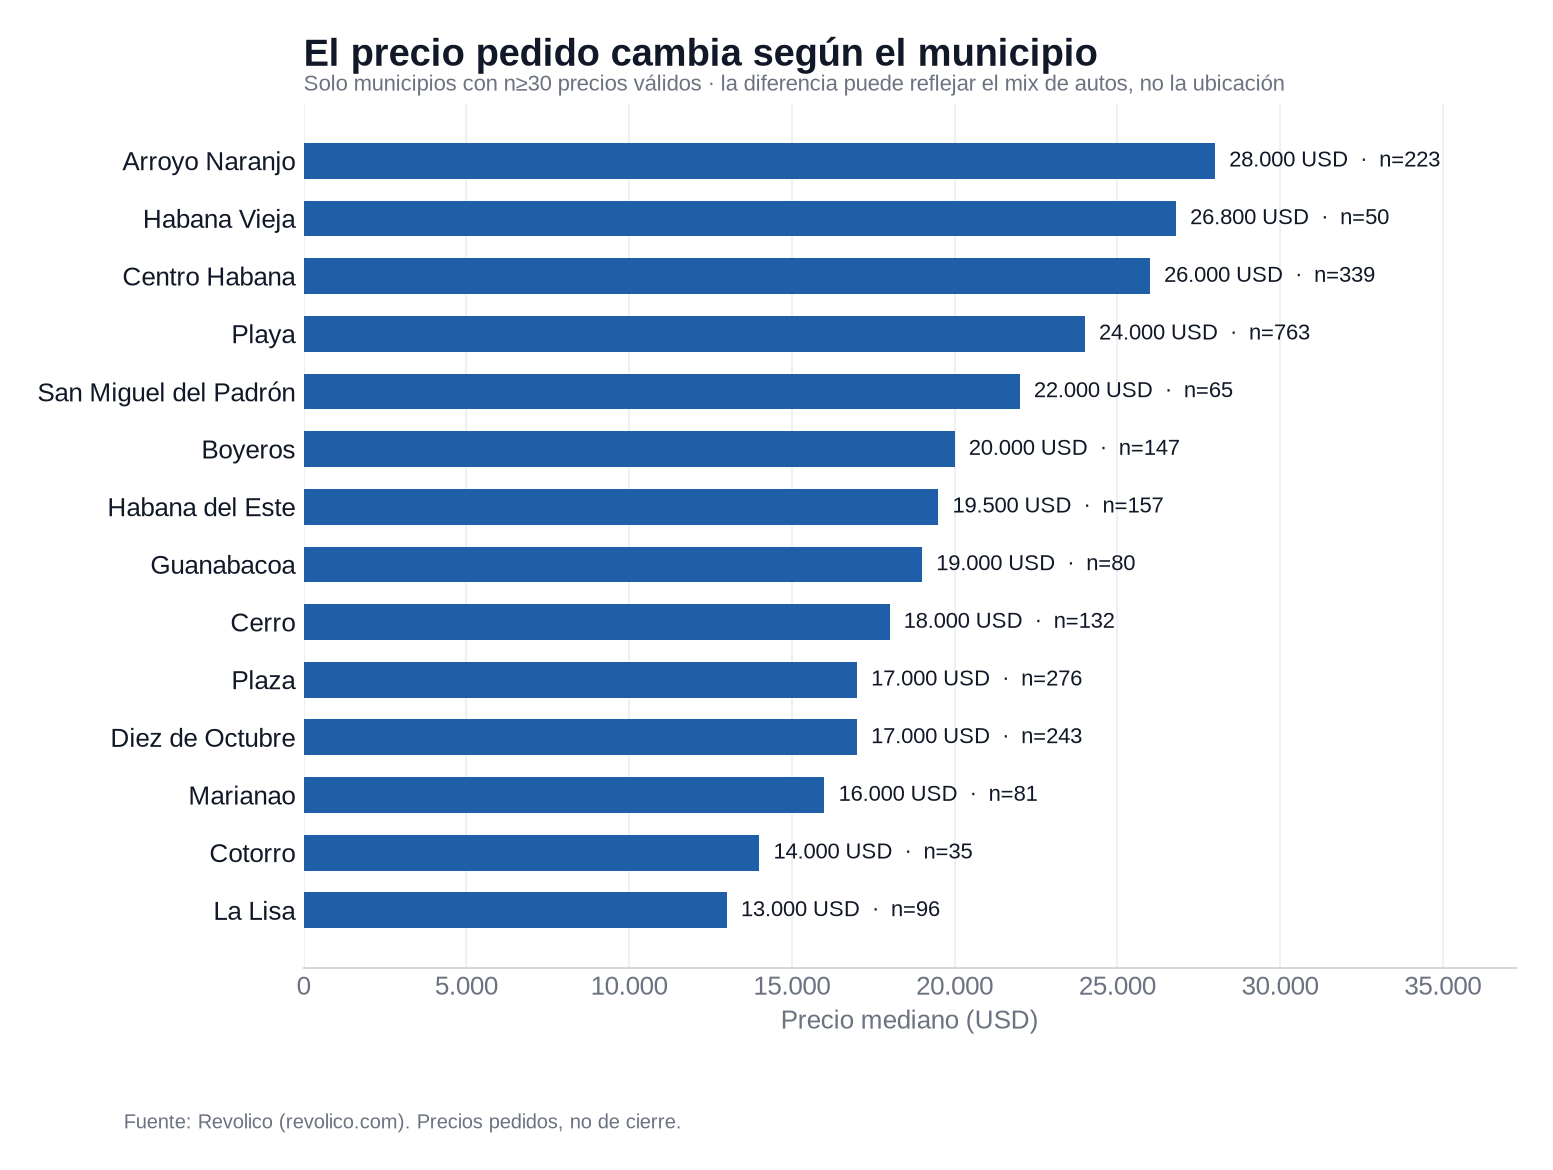

*Figura 4.11. Precio mediano por municipio con n≥30. Fuente: revolico.com; n=2.703.*

In [11]:
q8_all = (
    va.groupby("municipio")["precio_usd"]
      .agg(n="size", mediana="median",
           p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75))
      .reset_index()
)
q8_all["recortada_10"] = va.groupby("municipio")["precio_usd"].apply(media_recortada).reindex(q8_all["municipio"]).values
q8_all["Municipio"] = q8_all["municipio"].map(etiqueta_municipio)

q8 = q8_all[q8_all["n"] >= 30].sort_values("mediana", ascending=False)
tabla(q8[["Municipio", "n", "mediana", "recortada_10", "p25", "p75"]],
      enteros=["n"], usd=["mediana", "recortada_10", "p25", "p75"],
      titulo="Tabla 4.13. Precio por municipio con n≥30 (Q8). Base: 2.703.")

excl = q8_all[q8_all["n"] < 30]
print("\nMunicipios excluidos por n<30:")
tabla(excl[["Municipio", "n", "mediana"]], enteros=["n"], usd=["mediana"], titulo="Tabla 4.14. Municipios excluidos por n<30.")

grupos = [g["precio_usd"].values for _, g in va.groupby("municipio") if len(g) >= 30]
H, pvalor = stats.kruskal(*grupos)
print(f"\nKruskal-Wallis: H={H:.1f}, p={pvalor:.2e} · {len(grupos)} municipios con n≥30")
mostrar_figura("02_mediana_precio_por_municipio.png", titulo="Figura 4.11. Precio mediano por municipio con n≥30. Fuente: revolico.com; n=2.703.")

### 4.9 Q9 · ¿Cuánto cuesta mantener un auto?

**Respuesta:** mantener un auto en La Habana cuesta, y cuesta de formas muy distintas. En las **30 entrevistas procesadas**, el gasto anual declarado va de **200 USD** a **2.000–3.000 USD**. Dos casos no dieron un rango cerrado: uno lo describió como “bastante elevado” y otro dijo “no menos de 200 USD”.

#### El combustible es un gasto constante, pero no uniforme

Entre quienes declararon precio, el litro se movió entre **2,00 y 3,00 USD**; la mayoría entre **2,20 y 2,80 USD**, con compras en **CUPET, Mipymes** y “por la calle”. El consumo mensual varió desde **20–25 litros** hasta **130–160 litros** en uso intensivo. Un camión Chevrolet 1954 de carga se describió en **2,2 km por litro**, con rangos diarios de **40 a 100–200 litros**.

#### Las reparaciones no tienen una sola factura

Aparecieron estimados de **200 USD**, **200–300**, **200–400**, **300–500**, **400–800**, **1.000–2.000** y **2.000–3.000 USD** anuales. Un caso reportó **15k, 20k, 30k CUP** (≈19, 25 y 38 USD con tasa 788 CUP/USD). La variación depende del vehículo, el uso, las piezas y la magnitud de las averías.

#### Conseguir piezas suele ser la parte difícil

La dificultad se calificó como **alta** (24 menciones), **compleja** o asociada a **precios elevados**. Las fuentes incluyen **Mipymes**, **importadoras**, **internet**, **redes sociales**, **contactos que importan** y encargos al exterior.

#### Otros gastos

**29 de 30** entrevistados respondieron “ninguno” en otros gastos; un caso mencionó **neumáticos (60–80 USD)** y **baterías (300 USD)**. La ausencia de declaración no significa ausencia de gasto: solo refleja lo reportado.

> **Límite central:** 30 entrevistas no son una muestra representativa de los propietarios de La Habana. Son estimaciones declaradas, con rangos y valores faltantes; no se generalizan a toda la población.

In [12]:
texto = (DATA / "raw" / "entrevistas" / "Entrevistas.txt").read_text(encoding="utf-8")
partes = re.split(r"^Entrevista\s+(\d+)\s*$", texto, flags=re.M)
filas = []
for i in range(1, len(partes), 2):
    numero = int(partes[i])
    bloque = partes[i + 1]
    resp = {}
    for linea in bloque.splitlines():
        m = re.match(r"^(\d+)\s*-\s*(.*)$", linea.strip())
        if m:
            resp[int(m.group(1))] = m.group(2).strip().replace("*", "")
    filas.append({"id": numero, **{f"q{k}": resp.get(k, "") for k in range(1, 12)}})
ent = pd.DataFrame(filas)

def no_declarado(serie):
    return serie.astype(str).str.lower().str.strip().str.contains("no declarado").sum()

resumen_q9 = pd.DataFrame([
    ("Precio del litro", len(ent) - no_declarado(ent["q5"]), no_declarado(ent["q5"])),
    ("Fuente del combustible", len(ent) - no_declarado(ent["q4"]), no_declarado(ent["q4"])),
    ("Consumo mensual", len(ent) - no_declarado(ent["q3"]), no_declarado(ent["q3"])),
    ("Frecuencia de mantenimiento", len(ent) - no_declarado(ent["q6"]), no_declarado(ent["q6"])),
    ("Lugar de mantenimiento", len(ent) - no_declarado(ent["q7"]), no_declarado(ent["q7"])),
    ("Gasto anual con cifra o rango", int(len(ent) - ent["q10"].str.lower().str.contains("no puedo|no menos").sum()), int(ent["q10"].str.lower().str.contains("no puedo|no menos").sum())),
    ("Otros gastos", len(ent), 0),
], columns=["Campo", "Declarado", "No declarado"])
print("Cobertura de las respuestas (30 entrevistas):")
tabla(resumen_q9, enteros=["Declarado", "No declarado"], titulo="Tabla 4.15. Cobertura de las respuestas (30 entrevistas).")

precios_litro = []
for respuesta in ent["q5"]:
    precios_litro += [float(x.replace(",", ".")) for x in re.findall(r"\d+(?:[.,]\d+)?", respuesta)]
print(f"\nPrecio del litro declarado: {min(precios_litro):.2f}–{max(precios_litro):.2f} USD ({len(precios_litro)} valores)")
print(f"Dificultad 'alta': {ent['q8'].str.lower().str.contains('alta').sum()} · 'compleja': {ent['q8'].str.lower().str.contains('complej').sum()} · 'precios': {ent['q8'].str.lower().str.contains('precio').sum()}")
print(f"Otros gastos 'ninguno': {ent['q11'].str.lower().str.contains('ninguno').sum()} de {len(ent)}")

print("\nPrimeros 10 casos (tabla completa en el Anexo E):")
tabla(ent[["id", "q1", "q2", "q5", "q10"]].head(10), titulo="Tabla 4.16. Primeros 10 casos de entrevista (Q9).")

Cobertura de las respuestas (30 entrevistas):


**Tabla 4.15. Cobertura de las respuestas (30 entrevistas).**

,Campo,Declarado,No declarado
0,Precio del litro,29,1
1,Fuente del combustible,27,3
2,Consumo mensual,30,0
3,Frecuencia de mantenimiento,29,1
4,Lugar de mantenimiento,29,1
5,Gasto anual con cifra o rango,28,2
6,Otros gastos,30,0



Precio del litro declarado: 2.00–3.00 USD (55 valores)
Dificultad 'alta': 24 · 'compleja': 2 · 'precios': 7
Otros gastos 'ninguno': 29 de 30

Primeros 10 casos (tabla completa en el Anexo E):


**Tabla 4.16. Primeros 10 casos de entrevista (Q9).**

,id,q1,q2,q5,q10
0,1,Camion Chevrolet 1954,Carga de mercancia,"2, 2.10, 2.30 USD",No puedo dar un estimado pero diria que es bastante elevado.
1,2,Chevrolet 55,Uso propio,2.30 USD,"15k,20k,30k CUP (19,25,38 USD tasa de cambio 788 CUP = 1 USD)"
2,3,Kia Picanto,Uso personal,2.5 USD aproximadamente,200 USD anual
3,4,Lada 2101,Uso personal,2.60 USD,200-300 USD
4,5,BYD F3,Trabajo,no declarado,2000-3000 USD
5,6,Peugeot 301,Traslado personal,2.0-3.0 USD,300-400 USD aproximadamente pero ha llegado hasta 1000 USD
6,7,Lada 2107,Uso personal,2.20-2.70 USD,2000-3000 USD
7,8,Kia Picanto,Uso personal,2.0-2.40 USD,No menos de 200 USD
8,9,Lada 2107,Uso personal y mandados,2.20–2.60 USD,300–500 USD anuales
9,10,Hyundai Accent,Traslado al trabajo,2.30–2.50 USD,300–400 USD anuales


## 5. Discusión

### 5.1 Estructura y concentración

El mercado informal habanero está concentrado en pocas marcas y pocos municipios. Hyundai reúne casi una de cada cuatro publicaciones y Playa concentra más de una de cada cuatro. Esa concentración puede reflejar tanto la composición del parque como la forma en que se publica: concesionarios, revendedores y particulares no usan la misma plataforma con la misma intensidad.

La concentración **no es un indicador de competencia ni de disponibilidad**. Un municipio con pocos anuncios puede tener menos oferta publicada, pero también menos población, menos acceso a internet o menos cultura de publicar en Revolico.

### 5.2 Precios y brecha entre canales

La mediana informal (22.000 USD) es 10.699 USD menor que la formal (32.699). La brecha es consistente con la diferencia de productos: el catálogo formal es nuevo y el informal incluye usados de todas las edades. Cuando se compara por marca y solo con ≥10 anuncios informales, la brecha por marca va de 5.291 USD más en el informal (Foton) a 47.722 USD más en el formal (Mercedes-Benz), y sigue siendo descriptiva, no causal.

El dato más robusto es la **heterogeneidad**: la distribución informal va de 1.000 a 320.000 USD. Cualquier promedio único oculta esa realidad. Por eso el reporte usa mediana y media recortada, y muestra P25–P75.

### 5.3 Geografía

Las diferencias por municipio son estadísticamente detectables, pero el diseño no permite aislar el efecto de la ubicación. Un municipio puede ser “más caro” porque concentra marcas o modelos más caros, no porque el mismo auto cueste más allí. La interpretación causal exigiría controlar marca, modelo, año, estado y kilometraje, variables que en su mayoría faltan.

### 5.4 Antigüedad y datos faltantes

El 48,9% sin año es el hallazgo que más condiciona la lectura. Si los anuncios que declaran año son sistemáticamente distintos de los que no lo hacen (por ejemplo, vendedores más profesionales o autos más nuevos), la composición observada está sesgada. El reporte no imputa años: prefiere declarar la incertidumbre.

### 5.5 Mantenimiento

Las entrevistas muestran un costo anual que va de cientos a miles de USD, con el combustible como gasto recurrente y las piezas como cuello de botella. La variación no es ruido: depende del tipo de vehículo, el uso (personal, trabajo, carga) y la disponibilidad de piezas. La muestra es de conveniencia, así que sirve para **describir mecanismos**, no para estimar un promedio poblacional.

### 5.6 Implicaciones para un comprador

1. **Presupuestar el mantenimiento**, no solo la compra: 200–3.000 USD anuales en los casos entrevistados.
2. **Preguntar el año y el kilometraje** antes de comparar precios.
3. **Desconfiar de precios marcador** (1 USD, 1.111.111 USD) y de anuncios sin fotos o datos.
4. **Comparar canales con cautela**: un formal nuevo no es un informal usado.
5. **Revisar el municipio** como pista de composición, no como sentencia de precio.

### 5.7 Lo que estos datos no permiten afirmar

- No son precios de cierre ni transacciones.
- No representan todas las ventas ni todo el parque.
- No permiten comparar entidades formales entre sí.
- No permiten generalizar a Cuba.
- No permiten afirmar causalidad entre municipio y precio.

## 6. Limitaciones

| # | Sesgo o límite | Efecto | Mitigación en este reporte |
|---|---|---|---|
| 1 | Selección (solo Revolico) | No representa todas las ventas ni el universo de vehículos | Se declara; Q1 es proxy de publicaciones |
| 2 | Precios pedidos, no de cierre | El precio real puede diferir | Se llama “precio pedido”; no se infiere cierre |
| 3 | Información incompleta | 48,9% sin año; kilometraje mayoritariamente ausente | No se imputa; se reporta `n` por análisis |
| 4 | Precios marcador | 584 anuncios fuera de rango | Regla 1.000–999.999 USD; se documenta |
| 5 | Composición heterogénea | Comparar municipios/marcas mezcla años, modelos y estados | Se advierte; no se afirma causalidad |
| 6 | Catálogo formal acotado | 83 modelos, 4 entidades | El catálogo mide cobertura, no ventas; no se rankean entidades |
| 7 | Cruce formal-informal limitado | 6 marcas con ≥10 anuncios informales y presencia en catálogo | Se compara solo ese subconjunto |
| 8 | Entrevistas de conveniencia | 30 casos, no representativos | Se describen mecanismos, no poblaciones |
| 9 | Contexto temporal y cambiario | Precios y tasas cambian rápido | Fechas y tasas declaradas |
| 10 | Cobertura geográfica | Solo La Habana | No se extrapola a Cuba |
| 11 | Errores de verificación | 811 anuncios con error de red en La Habana | Se distingue “error” de “despublicado” |
| 12 | Base de cálculo | 2.703 (todos) vs. 2.015 (activos) | Se declara; la mediana no cambia (22.000) |

**Limitaciones técnicas adicionales:**

- El dataset de 3.566 anuncios incluye filas no activas; se conservan para no perder información y se declara la base.
- La verificación se hizo el 2026-10-26; los anuncios pueden haber cambiado después.
- Los modelos contienen ruido de parseo (títulos como “Toyota Corcel interesados llamar…”).
- No hay datos de kilometraje, estado mecánico ni papeles, variables clave para el precio.

## 7. Conclusiones

1. **Q1 — Publicaciones:** Hyundai lidera con 872 anuncios (24,5%); el 31,1% no declara marca. Es un proxy de publicaciones, no de ventas.
2. **Q2 — Precios por marca:** las medianas con `n≥30` van de 5.500 USD (Fiat) a 46.000 USD (BMW); Hyundai, la más publicada, tiene 29.000 USD.
3. **Q3 — Precio y año:** asociación positiva (Spearman ρ=0,65; n=1.519), con medianas de 12.000 USD en los 2000 a 33.000 USD en los 2020. La relación no es lineal.
4. **Q4 — Marcas más caras:** BMW (46.000, n=33), Dongfeng (35.000, n=32) y Honda (32.250, n=74). Foton (50.000) queda fuera por n=10.
5. **Q5 — Clásicos y modernos:** 69 clásicos (3,8%) y 1.752 modernos (96,2%) entre 1.821 con año; 1.745 (48,9%) no declaran año.
6. **Q6 — Brecha:** 22.000 vs. 32.699 USD (10.699 USD). Seis marcas son comparables; la dirección no es uniforme: el informal pide más en Dongfeng, Foton, MG y Toyota, y el formal es más caro en Nissan y Mercedes-Benz.
7. **Q7 — Municipios:** Playa concentra 1.002 anuncios (28,1%); top 3 = 51,4%.
8. **Q8 — Municipio y precio:** medianas de 13.000 (La Lisa) a 28.000 USD (Arroyo Naranjo) con n≥30; diferencias significativas, pero confundidas por composición.
9. **Q9 — Mantenimiento:** 200–3.000 USD anuales en 30 entrevistas; combustible y piezas explican la variación. Muestra no representativa.

**Contribuciones:**

- Un dataset documentado para un mercado sin datos públicos.
- Una comparación formal-informal con reglas explícitas y cautelas.
- Un pipeline reproducible (notebook, figuras, web) que permite auditar cada cifra.

**Trabajo futuro:**

- Incorporar kilometraje, estado mecánico, combustible y papeles para mejorar la comparación.
- Ampliar la cobertura del catálogo formal y repetir la captura en el tiempo.
- Revisar la evolución de precios con una serie temporal.
- Convertir las entrevistas en un instrumento estructurado y ampliar la muestra.

## 8. Referencias

**Fuentes de datos**

- Revolico. (2026). *Carros en La Habana* [clasificados]. https://www.revolico.com (consulta: 2026-09-24 y 2026-10-26).
- BDC ONE. (2026). *Catálogo de autos*. https://bdcone.online (consulta: 2026-10-11).
- Dongfeng Cuba. (2026). *Catálogo de modelos*. https://dongfengqba.com (consulta: 2026-10-11).
- MCV Comercial. (2026). *Catálogo de vehículos*. https://mcvcommercial.com (consulta: 2026-10-11).
- CIMEX. (2026). *Catálogo de vehículos*. https://cimex.cu (consulta: 2026-10-11).

**Datasets del proyecto**

- ProyectoCD. (2026). *anuncios_analisis.csv* [dataset]. `data/interim/anuncios_analisis.csv`.
- ProyectoCD. (2026). *comercializadoras.csv* [dataset]. `data/processed/comercializadoras.csv`.
- ProyectoCD. (2026). *Entrevistas.txt* [entrevistas procesadas]. `data/raw/entrevistas/Entrevistas.txt`.
- ProyectoCD. (2026). *verificacion_anuncios.csv* [verificación de URLs]. `data/raw/clasificados/revolico/verificacion_anuncios.csv`.

**Documentación y reproducibilidad**

- ProyectoCD. (2026). *Preguntas de investigación*. `docs/preguntas_investigacion.md`.
- ProyectoCD. (2026). *Diccionario de datos*. `docs/diccionario_datos.md`.
- ProyectoCD. (2026). *Plan de implementación web*. `docs/plan_implementacion_web.md`.
- ProyectoCD. (2026). *Reporte de correcciones de figuras*. `reports/figuras/Analizar/reporte_correcciones.md`.

**Herramientas**

- pandas 3.0.5, NumPy 2.5.3, Matplotlib 3.11.2, SciPy 1.18.1, scikit-learn 1.9.1, Jupyter (Python 3.14.8).

## 9. Anexos

### Anexo A · Diccionario de datos (variables principales)

| Variable | Tipo | Descripción | Regla |
|---|---|---|---|
| `fuente` | texto | Origen del registro | Revolico / comercializadora |
| `fecha` | fecha | Fecha de captura o consulta | 2026 |
| `provincia` | texto | Provincia | Solo La Habana en el análisis |
| `municipio` | texto | Municipio | 15 municipios; 2 sin dato |
| `marca` | texto | Marca normalizada | “no identificada” si falta |
| `modelo` | texto | Modelo detectado | Puede contener ruido |
| `anio` | int | Año de fabricación | 0 = ausente; rango 1950–2026 |
| `precio_original` | float | Precio tal como aparece | — |
| `moneda` | texto | USD / CUP / EUR | — |
| `precio_usd` | float | Precio convertido a USD | Válido: 1.000–999.999 |
| `km` | float | Kilometraje | Mayoritariamente ausente |
| `combustible` | texto | Tipo de combustible | — |
| `transmision` | texto | Transmisión | — |
| `vistas` | int | Visualizaciones | — |
| `estado_verificacion` | texto | Estado de la URL | activo / error / despublicado / eliminado / expirado |
| `entidad` | texto | Comercializadora | Solo formal |
| `clase` | texto | Auto, camioneta, microbús… | Solo formal |
| `propulsion` | texto | Gasolina, diésel, eléctrico… | Solo formal |

> Diccionario completo y reglas de integración: `docs/diccionario_datos.md`.

### Anexo B · Scripts y comandos

```bash
# 1. Preprocesamiento y variables
python src/preprocesamiento.py
python src/generar_variables.py

# 2. Datos y figuras de la web (misma fuente que este reporte)
python src/exportar_datos_web.py
MPLCONFIGDIR=/tmp/mpl python src/generar_figuras_web.py

# 3. Ejecutar este notebook de principio a fin
jupyter nbconvert --to notebook --execute --inplace \
  notebooks/reporte_completo_mercado_automotriz.ipynb
```

- Entorno: `.venv` con `requirements-lock.txt`.
- Python 3.14.8.
- Commit de referencia: `dc0951a` (la celda de entorno imprime el actual).
- El commit `dc0951a` es la base de datos/código; los cambios de este reporte y de la web están en el working tree hasta que se registren.

### Anexo C · Instrumento de entrevista

Las 30 entrevistas siguen 11 preguntas:

1. ¿Cuál es la marca y el modelo de su auto?
2. ¿Cuál es el uso principal que le da?
3. En un mes normal, ¿cuántos litros de gasolina necesita?
4. ¿Cómo adquiere el combustible habitualmente?
5. ¿Cuál es el precio por litro que paga?
6. ¿Con qué frecuencia realiza mantenimiento preventivo?
7. ¿Dónde realiza el mantenimiento?
8. ¿Cómo calificaría la dificultad para conseguir piezas?
9. ¿Dónde suele conseguir las piezas?
10. ¿Cuál es su gasto anual estimado en reparaciones y mantenimiento?
11. Además del combustible y el mantenimiento, ¿qué otros gastos implica tener un auto?

> Las entrevistas están procesadas como resúmenes, no como transcripciones verbatim. No se publican datos personales.

### Anexo D · Verificación de anuncios

| Estado | Universo nacional (3.958 URLs) | La Habana (3.566 anuncios) |
|---|---:|---:|
| activo | 2.997 | 2.650 |
| error de verificación | 856 | 811 |
| despublicado | 66 | 66 |
| eliminado | 37 | 37 |
| expirado | 2 | 2 |

- Verificación: 2026-10-26, 17:36 UTC.
- Códigos HTTP: 200 (3.102), ConnectionError (839), ReadTimeout (17).
- **Un error de conexión no significa que el anuncio no exista**: solo que no se pudo confirmar en ese momento.

### Anexo E · Tabla completa de entrevistas

La tabla completa de los 30 casos está en la celda siguiente. Incluye vehículo, uso, consumo, precio del litro y gasto anual declarado.

### Anexo F · Checklist de cumplimiento

- [x] Responde Q1–Q9 con datos.
- [x] Declara fuente y `n` en cada figura/tabla.
- [x] Aplica las reglas de precio, marca, año y calidad de la muestra informal.
- [x] Declara los sesgos y limitaciones.
- [x] Incluye referencias y anexos.
- [x] Es reproducible desde los CSV y el notebook.
- [x] Distingue precios pedidos de precios de lista y de cierre.
- [ ] Exportar a HTML/PDF si la entrega lo exige.

In [13]:
print("Tabla completa de entrevistas (30 casos):")
tabla(
    ent[["id", "q1", "q2", "q3", "q5", "q10"]]
    .rename(columns={
        "id": "ID", "q1": "Vehículo", "q2": "Uso", "q3": "Consumo",
        "q5": "Precio/litro", "q10": "Gasto anual declarado",
    }),
    titulo="Tabla E.1. Tabla completa de entrevistas (30 casos)."
)

Tabla completa de entrevistas (30 casos):


**Tabla E.1. Tabla completa de entrevistas (30 casos).**

,ID,Vehículo,Uso,Consumo,Precio/litro,Gasto anual declarado
0,1,Camion Chevrolet 1954,Carga de mercancia,"2.2 kilometros por litro, desde 40 litros diarios hasta 100 o 200 litros diarios","2, 2.10, 2.30 USD",No puedo dar un estimado pero diria que es bastante elevado.
1,2,Chevrolet 55,Uso propio,20-25 litros mensuales,2.30 USD,"15k,20k,30k CUP (19,25,38 USD tasa de cambio 788 CUP = 1 USD)"
2,3,Kia Picanto,Uso personal,20-25 litros,2.5 USD aproximadamente,200 USD anual
3,4,Lada 2101,Uso personal,80 litros mensuales,2.60 USD,200-300 USD
4,5,BYD F3,Trabajo,60-80 litros mensuales,no declarado,2000-3000 USD
5,6,Peugeot 301,Traslado personal,20 litros,2.0-3.0 USD,300-400 USD aproximadamente pero ha llegado hasta 1000 USD
6,7,Lada 2107,Uso personal,80-90 litros,2.20-2.70 USD,2000-3000 USD
7,8,Kia Picanto,Uso personal,100 litros,2.0-2.40 USD,No menos de 200 USD
8,9,Lada 2107,Uso personal y mandados,60–70 litros mensuales,2.20–2.60 USD,300–500 USD anuales
9,10,Hyundai Accent,Traslado al trabajo,50–60 litros mensuales,2.30–2.50 USD,300–400 USD anuales


### Declaración de alcance y herramientas

Este reporte se apoya en los datos del repositorio `ProyectoCD`. Las cifras se calcularon con pandas/NumPy y se verifican en las celdas de control. No se imputaron valores ni se inventaron datos. Las figuras 03, 04 y 07 fueron regeneradas para corregir la etiqueta Foton/Ford, mostrar `n` y evitar el ranking de entidades por precio. La página `web/` es un producto de comunicación complementario; este documento se basta a sí mismo.

**Fin del reporte.**